# SA1 Electricity Price — Historical Analysis, Prediction & Live Rate

**Goal:** for any given time, return
1. a **predicted** wholesale spot price (RRP, $/MWh) for South Australia (`SA1`), and
2. the **actual** price at that time — from AEMO history if it's in the past, or live from OpenElectricity if it's recent,

and use the forecasts to plan **when to import / charge** (cheapest periods) and **when to export** solar or battery power (most expensive periods) over the next few hours to days — see `plan_next()` in section 10.

**Data sources**
| Purpose | Source | How |
|---|---|---|
| Historical (~5 yrs, 5-minute) | AEMO NEMWeb `DISPATCHPRICE` table | `nemosis` → `data/sa1_dispatch_price.csv` (built by `scripts/download_history.py`) |
| AEMO's own forecasts (pre-dispatch, all runs since 2021) | AEMO NEMWeb `PREDISPATCHPRICE` archive | `scripts/download_predispatch.py` → `data/sa1_predispatch.csv` |
| Live / recent prices | OpenElectricity API v4 | `openelectricity` SDK, `MarketMetric.PRICE`, 5m interval, `network_region=SA1` |
| Live AEMO forecasts | NEMWeb `Reports/Current/PredispatchIS_Reports` (public, no key) | latest runs cached in `data/sa1_predispatch_live.csv` |

**Time convention:** all timestamps are **NEM time (AEST, UTC+10, no daylight saving)** and refer to the **end** of each 5-minute dispatch interval — the same convention AEMO uses for `SETTLEMENTDATE`. Adelaide local time is 30 min **behind** NEM time in winter (ACST, UTC+9:30) and 30 min **ahead** during daylight saving, early October to early April (ACDT, UTC+10:30), so `price_at()`, `plan_next()` and `day_segments()` accept a `tz=` argument if you'd rather work in Adelaide time.

**Setup:** put your free API key from platform.openelectricity.org.au in a `.env` file next to this notebook:
```
OPENELECTRICITY_API_KEY=your_key_here
```
Everything except the live-price sections works without a key.

## How this notebook works

**In one sentence:** it learns from 5 years of South Australian wholesale electricity prices and AEMO's own forecasts, then predicts the price for any time — minutes to days ahead — and tells you the cheapest times to buy/charge and the most expensive times to export.

**The pipeline**

```
 AEMO price history ──┐                                         ┌──► price_at()      one time: predicted vs actual
 (nemosis, 5 yrs)     │                                         │
                      ├──► features ──► 9 horizon models ──────┼──► plan_next()     cheapest / dearest windows
 AEMO pre-dispatch ───┤    (calendar,   (5 min … 48 h)  +      │
 forecasts (5 yrs)    │     recent       seasonal model         ├──► day_segments()  cost of each part of the day
                      │     prices,      (> 48 h)               │
 Live prices (API) ───┤     AEMO fcst)        │                 └──► current_price() latest actual price
 Live AEMO forecasts ─┘                       ▼
                                   tested on 6 unseen months, P10–P90 band calibrated
```

**Section map**

| # | Section | What it does |
|---|---|---|
| 1 | Setup | Libraries, constants, chart style, loads the API key from `.env` |
| 2 | Historical data | Loads 5 years of AEMO 5-minute prices (`data/sa1_dispatch_price.csv`) |
| 3 | Exploratory analysis | Trends, spikes/negative prices by year, daily "duck curve", weekday × hour heatmap; loads AEMO's past forecasts |
| 4 | Feature engineering | Turns raw prices into model inputs — calendar, recent prices, AEMO's forecast — one table per horizon |
| 5 | Train / test split | Holds out the last 6 months; trains low/median/high (P10/P50/P90) models for each horizon |
| 6 | Evaluation | Error by horizon vs simple baselines and AEMO; charts; buy/sell timing test; calibrates the P10–P90 band |
| 7 | Refit | Retrains everything on all the data for live use |
| 8 | Live data | Live prices from OpenElectricity and live AEMO forecasts from NEMWeb |
| 9 | Ask for a price | `price_at()` / `compare()` — predicted vs actual price for any time |
| 10 | Buy / export planning | `plan_next()` windows, `day_segments()` part-of-day summary, live accuracy check |
| 11 | Notes & limitations | What the models can and can't do, how to refresh the data |
| 12 | Enter a date and time | Type any date and time (or use the form) to get the predicted price |
| 13 | Daily solar / grid plan | Half-hour plan for a day: when to export solar, self-use, or take from the grid |

**Quick start**

1. Select the **Python (PriceAPI)** kernel and run all cells (~15 minutes, mostly model training in sections 5 and 7).
2. Then, at any time, re-run sections 8–10 (or call the functions in a new cell) for fresh forecasts:

| Call | Answers |
|---|---|
| `current_price()` | What is the price right now? |
| `price_at("2026-10-23 18:30", tz="Australia/Adelaide")` | What will (or did) the price be at this time? |
| `plan_next(hours=48, window="2h", tz="Australia/Adelaide")` | When should I charge / import, and when should I export? |
| `day_segments(days=2, tz="Australia/Adelaide")` | Which part of today and tomorrow is cheap or expensive? |
| `daily_plan("tomorrow")` | When should we export solar, and when should we take from the grid? |

Or jump to **section 12** at the end and type a date and time.

Prices are wholesale **$/MWh**; divide by 10 for **c/kWh**.

## 1. Setup

Imports the libraries (pandas for data, LightGBM for the models, matplotlib for charts, `holidays` for SA public holidays), sets the constants used throughout, defines the chart style, and reads the OpenElectricity API key from `.env`.

In [1]:
# SETUP — libraries, file paths, constants and chart style used everywhere below.
#   • NEM_TZ: the NEM runs on AEST (UTC+10) all year — no daylight saving.
#   • STEP / PER_DAY: prices come in 5-minute intervals, 288 per day.
#   • .env is read here so the OpenElectricity API key is available later.

import os, warnings
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import lightgbm as lgb
import holidays
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
load_dotenv(".env")

DATA = Path("data")
HIST_CSV = DATA / "sa1_dispatch_price.csv"
REGION = "SA1"
NEM_TZ = "Etc/GMT-10"          # fixed UTC+10 (AEST), what the NEM runs on
STEP = pd.Timedelta("5min")
PER_DAY = 288                  # 5-minute intervals per day

# Chart styling — recessive axes/grid, thin marks, a fixed series order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # actual / prediction / baseline-or-band
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (12, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 1.5,
    "legend.frameon": False,
})

## 2. Historical data (AEMO via nemosis)

The CSV is produced by `scripts/download_history.py`, which calls
`nemosis.dynamic_data_compiler(..., 'DISPATCHPRICE', filter_cols=['REGIONID'], filter_values=(['SA1'],))`
month by month, keeps only the non-intervention price (`INTERVENTION == 0`), and caches the raw AEMO archives in `nem_cache/`.
Run the cell below once to (re)build it — it's skipped if the CSV already exists.

In [2]:
# LOAD HISTORY — read the 5 years of AEMO 5-minute SA1 prices (downloading them first if needed),
# put them on a continuous 5-minute timeline and fill only tiny gaps (≤ 30 min).
# Result: `price`, a pandas Series indexed by NEM-time interval end, values in $/MWh.

if not HIST_CSV.exists():
    !python scripts/download_history.py "2021/10/01 00:00:00" "{datetime.now():%Y/%m/01 00:00:00}"

hist = pd.read_csv(HIST_CSV, parse_dates=["SETTLEMENTDATE"])
price = (hist.set_index("SETTLEMENTDATE")["RRP"].astype(float).sort_index())
price = price[~price.index.duplicated()]

full_index = pd.date_range(price.index.min(), price.index.max(), freq=STEP)
print(f"{len(price):,} intervals  |  {price.index.min()} → {price.index.max()}")
print(f"Missing intervals: {len(full_index) - len(price):,}")
price = price.reindex(full_index).interpolate(limit=6)   # fill short gaps only (≤30 min)
price.describe().round(2)

525,888 intervals  |  2021-10-01 00:05:00 → 2026-10-01 00:00:00
Missing intervals: 0


count    525888.00
mean         98.74
std         480.00
min       -1000.00
25%           0.00
50%          67.58
75%         136.04
max       20300.00
Name: RRP, dtype: float64

## 3. Exploratory analysis

Before modelling, three views of the history show what drives SA prices:

1. **Long-term trend** — daily averages over 5 years, plus how often prices go negative or spike above $300/MWh each year.
2. **Daily shape by season** — the "duck curve": prices collapse (often below zero) in the middle of the day when rooftop and utility solar flood the grid, then jump in the evening when solar fades and demand peaks.
3. **Weekday × hour heatmap** — how much weekends and particular hours differ.

Medians are used rather than averages because a handful of extreme spikes (up to $20,300/MWh) would distort the average.

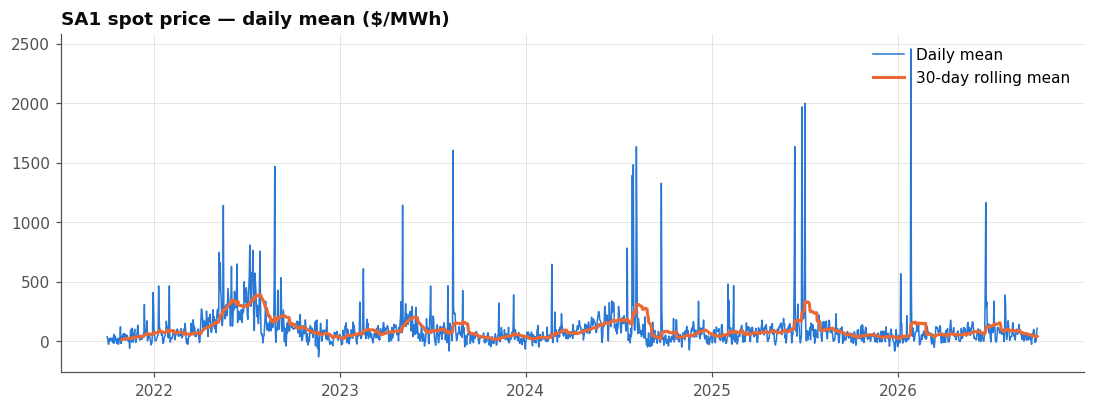

Share of intervals with negative price, by year:
2021    26.9%
2022    18.7%
2023    24.7%
2024    25.1%
2025    30.4%
2026    23.9%

Share of intervals above $300/MWh, by year:
2021     0.68%
2022    14.38%
2023     3.74%
2024     2.63%
2025     1.66%
2026     1.76%


In [3]:
# EDA 1 — long-term trend: daily average price with a 30-day rolling average,
# plus how often prices were negative or above $300/MWh in each year.

daily = price.resample("D").mean()
fig, ax = plt.subplots()
ax.plot(daily.index, daily, color=SERIES[0], linewidth=1, label="Daily mean")
ax.plot(daily.index, daily.rolling(30).mean(), color=SERIES[1], linewidth=2, label="30-day rolling mean")
ax.set_title("SA1 spot price — daily mean ($/MWh)")
ax.legend(loc="upper right")
plt.show()

print("Share of intervals with negative price, by year:")
print((price < 0).groupby(price.index.year).mean().map("{:.1%}".format).to_string())
print("\nShare of intervals above $300/MWh, by year:")
print((price > 300).groupby(price.index.year).mean().map("{:.2%}".format).to_string())

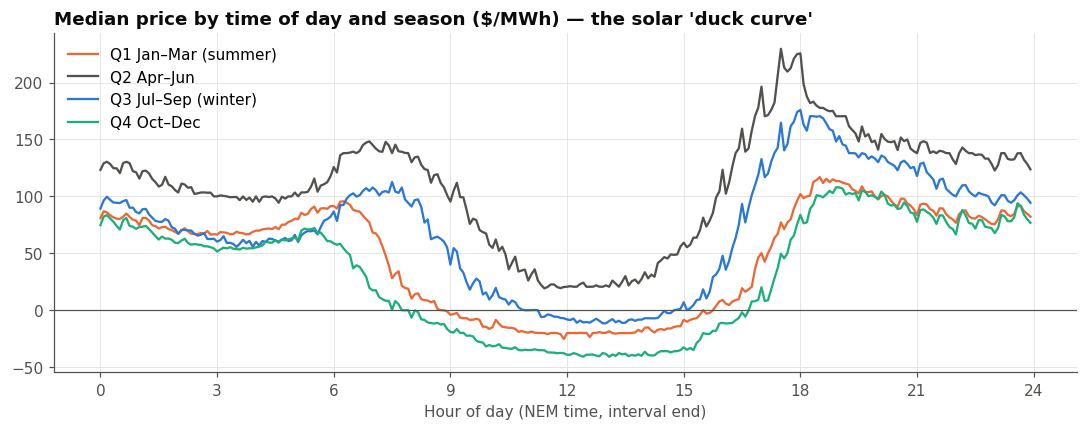

In [4]:
# EDA 2 — the daily shape ("duck curve"): median price for each time of day, one line per season.
# Shows the cheap/negative midday solar dip and the expensive evening peak.

# Median price by time of day — medians, because $17,500 spikes swamp the mean
tod = price.groupby([price.index.quarter, price.index.hour + price.index.minute / 60]).median().unstack(0)
fig, ax = plt.subplots()
labels = {1: "Q1 Jan–Mar (summer)", 2: "Q2 Apr–Jun", 3: "Q3 Jul–Sep (winter)", 4: "Q4 Oct–Dec"}
colors = {1: SERIES[1], 2: MUTED, 3: SERIES[0], 4: SERIES[2]}
for q in tod.columns:
    ax.plot(tod.index, tod[q], color=colors[q], label=labels[q])
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Hour of day (NEM time, interval end)")
ax.set_title("Median price by time of day and season ($/MWh) — the solar 'duck curve'")
ax.legend()
plt.show()

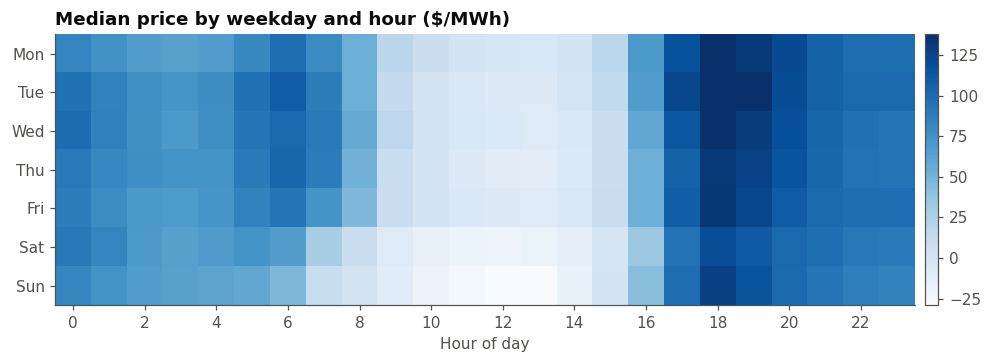

In [5]:
# EDA 3 — weekday × hour heatmap of median price: are weekends cheaper? which hours are worst?

# Hour × weekday heatmap of median price (single-hue sequential scale)
hm = price.groupby([price.index.dayofweek, price.index.hour]).median().unstack(1)
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(hm, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day"); ax.grid(False)
ax.set_title("Median price by weekday and hour ($/MWh)")
fig.colorbar(im, ax=ax, pad=0.01)
plt.show()

### AEMO pre-dispatch forecasts

Every 30 minutes AEMO publishes its own **pre-dispatch** price forecast for each half-hour out to the end of the next trading day (roughly 16–40 h ahead), built from generator bids, demand and wind/solar forecasts. These are the strongest single predictor of near-term price, so the models use them as an input.

`scripts/download_predispatch.py` pulls every pre-dispatch run since Oct 2021 from AEMO's monthly archive (`PREDISPATCHPRICE`, all runs) into `data/sa1_predispatch.csv`. AEMO's archive is missing Oct 2022; the models simply treat those rows as "no AEMO forecast available".

In [6]:
# LOAD AEMO FORECASTS — every pre-dispatch run since Oct 2021 (downloaded by scripts/download_predispatch.py).
# Each row: when AEMO published the forecast (ISSUED), which half-hour it is for (PERIOD_END), and the price (RRP).

PD_CSV = DATA / "sa1_predispatch.csv"
if not PD_CSV.exists():
    !python scripts/download_predispatch.py 2021-10 "{(pd.Timestamp.now().to_period('M') - 1)}"
pd_hist = pd.read_csv(PD_CSV, parse_dates=["ISSUED", "PERIOD_END"])
lead_h = (pd_hist["PERIOD_END"] - pd_hist["ISSUED"]).dt.total_seconds() / 3600
print(f"{len(pd_hist):,} SA1 forecasts from {pd_hist['ISSUED'].nunique():,} runs  |  "
      f"{pd_hist['ISSUED'].min():%Y-%m-%d} → {pd_hist['ISSUED'].max():%Y-%m-%d}  |  lead time {lead_h.min():.1f}–{lead_h.max():.1f} h")

4,781,502 SA1 forecasts from 86,155 runs  |  2021-10-01 → 2026-10-01  |  lead time 0.0–39.5 h


## 4. Feature engineering

How well you can predict a price depends mostly on **how far ahead** you're predicting — the *horizon* — measured from the last price you actually know. So instead of one model, there's a family:

| Model | Uses | When it's used |
|---|---|---|
| **Horizon models** — 5 min, 30 min, 1 h, 3 h, 6 h, 12 h, 24 h, 36 h, 48 h ahead | calendar **+** the latest known price and recent price statistics **+** AEMO's latest pre-dispatch forecast, all as of *horizon* before the target | target is ≤ 48 h after the last known price |
| **Seasonal** | calendar only — time of day, weekday, month, day-of-year, SA public holidays, long-term trend | target is more than 48 h ahead |

`price_at()` works out the gap between the target time and the last known price (AEMO history + live API) and uses the shortest-horizon model that covers it — e.g. a target 2 h away uses the 3 h model. Each horizon-*k* model only sees data that is at least *k* old, so it never peeks at prices it wouldn't have had. The 5-minute "model" is simply the latest known price (persistence), which beats any trained model that close in.

All models are LightGBM **quantile** models (P10 / P50 / P90). SA prices are heavy-tailed (−$1,000 to +$17,500), so the median is a far more stable point forecast than the mean, and the P10–P90 band shows how uncertain a given time is. LightGBM handles missing inputs natively, so when no AEMO forecast covers a target (e.g. beyond ~40 h) the model falls back on the price features.

In [7]:
# FEATURE ENGINEERING — builds the model inputs.
#   calendar_features(): time of day, weekday, holidays, season (no price data needed → works for any date)
#   price_features(s, k): recent price statistics, all at least k intervals old (so a k-ahead model can't cheat)
#   aemo_features(): AEMO's forecast for each target half-hour from the latest run published before the cut-off
# `frames` holds one training table per forecast horizon (5 min … 48 h).

SA_HOLIDAYS = holidays.Australia(subdiv="SA", years=range(2015, 2035))
T0 = pd.Timestamp("2021-10-01")

HORIZONS = {"5min": 1, "30min": 6, "1h": 12, "3h": 36, "6h": 72, "12h": 144,
            "24h": 288, "36h": 432, "48h": 576}                       # in 5-min steps
CAL_FEATURES = ["slot", "hour", "dow", "is_weekend", "is_holiday", "month",
                "doy_sin", "doy_cos", "days_since_start"]
H_FEATURES = ["last", "mean_1h", "mean_24h", "std_24h", "max_24h", "prev_week_mean",
              "same_slot_yday", "same_slot_lastwk", "same_slot_median_7d", "aemo", "aemo_lead_h"]
FEATURES = CAL_FEATURES + H_FEATURES

def calendar_features(idx: pd.DatetimeIndex) -> pd.DataFrame:
    # Interval-ending timestamps: 00:00 belongs to the previous day's last interval
    start = idx - STEP
    doy = start.dayofyear
    return pd.DataFrame({
        "slot": (start.hour * 12 + start.minute // 5),
        "hour": start.hour,
        "dow": start.dayofweek,
        "is_weekend": (start.dayofweek >= 5).astype(int),
        "is_holiday": np.array([d in SA_HOLIDAYS for d in start.date]).astype(int),
        "month": start.month,
        "doy_sin": np.sin(2 * np.pi * doy / 365.25),
        "doy_cos": np.cos(2 * np.pi * doy / 365.25),
        "days_since_start": (start - T0).days,
    }, index=idx)

def price_features(s: pd.Series, k: int) -> pd.DataFrame:
    # s must be on a continuous 5-minute grid; every feature is ≥ k steps old
    d = PER_DAY
    ds = d * int(np.ceil(k / d))                 # most recent "same time of day" that is ≥ k old
    roll_day = s.rolling(d, min_periods=d // 2)
    same_slot = pd.concat([s.shift(ds + d * j) for j in range(7)], axis=1)
    return pd.DataFrame({
        "last": s.shift(k),                                        # latest known price
        "mean_1h": s.rolling(12, min_periods=6).mean().shift(k),
        "mean_24h": roll_day.mean().shift(k),
        "std_24h": roll_day.std().shift(k),
        "max_24h": roll_day.max().shift(k),
        "prev_week_mean": s.rolling(7 * d, min_periods=d).mean().shift(k),
        "same_slot_yday": s.shift(ds),                             # same time, latest known day
        "same_slot_lastwk": s.shift(max(7 * d, ds)),               # same time last week
        "same_slot_median_7d": same_slot.median(axis=1),
    }, index=s.index)

def aemo_features(idx: pd.DatetimeIndex, cutoff, pdp: pd.DataFrame) -> pd.DataFrame:
    # AEMO's forecast for each target's half-hour from the latest run published at or before `cutoff`
    cutoff = pd.Series(pd.DatetimeIndex(cutoff) if np.ndim(cutoff) else [cutoff] * len(idx), index=idx)
    left = pd.DataFrame({"t": idx, "cutoff": cutoff.values, "PERIOD_END": idx.ceil("30min")}).sort_values("cutoff")
    m = pd.merge_asof(left, pdp.sort_values("ISSUED"), left_on="cutoff", right_on="ISSUED",
                      by="PERIOD_END", direction="backward", tolerance=pd.Timedelta("2h"))
    m = m.set_index("t").reindex(idx)
    return pd.DataFrame({"aemo": m["RRP"].values,
                         "aemo_lead_h": ((idx - m["ISSUED"]).dt.total_seconds() / 3600).values}, index=idx)

cal_all = calendar_features(price.index)
frames = {name: cal_all.join(price_features(price, k))
                       .join(aemo_features(price.index, price.index - k * STEP, pd_hist))
                       .assign(y=price).astype(np.float32)          # float32 keeps 9 frames in memory
          for name, k in HORIZONS.items()}
print("Share of intervals with an AEMO forecast available, by horizon:")
print(pd.Series({n: f["aemo"].notna().mean() for n, f in frames.items()}).map("{:.0%}".format).to_string())
frames["1h"].tail()

Share of intervals with an AEMO forecast available, by horizon:
5min     98%
30min    98%
1h       98%
3h       98%
6h       98%
12h      98%
24h      63%
36h      14%
48h       0%


,slot,hour,dow,is_weekend,is_holiday,month,doy_sin,doy_cos,days_since_start,last,...,mean_24h,std_24h,max_24h,prev_week_mean,same_slot_yday,same_slot_lastwk,same_slot_median_7d,aemo,aemo_lead_h,y
2026-09-30 23:40:00,283.0,23.0,2.0,0.0,0.0,9.0,-0.99987,-0.016127,1825.0,106.953018,...,75.130493,33.737114,142.669998,47.975193,31.029369,120.300003,63.893131,101.040001,1.135278,132.654114
2026-09-30 23:45:00,284.0,23.0,2.0,0.0,0.0,9.0,-0.99987,-0.016127,1825.0,104.422119,...,75.493034,33.487141,142.669998,47.969536,23.420000,120.300003,58.562840,101.040001,1.218611,142.669998
2026-09-30 23:50:00,285.0,23.0,2.0,0.0,0.0,9.0,-0.99987,-0.016127,1825.0,103.423264,...,75.852112,33.228374,142.669998,47.964008,30.663971,107.216789,57.436279,101.040001,1.301944,142.674637
2026-09-30 23:55:00,286.0,23.0,2.0,0.0,0.0,9.0,-0.99987,-0.016127,1825.0,104.264008,...,76.206848,32.982704,142.669998,47.960560,36.125259,109.477257,55.577179,101.040001,1.385278,103.395691
2026-10-01 00:00:00,287.0,23.0,2.0,0.0,0.0,9.0,-0.99987,-0.016127,1825.0,103.687668,...,76.559578,32.729649,142.669998,47.955181,30.232700,111.699333,50.570999,101.040001,1.468611,108.445847


## 5. Train / test split

Time-based split — models are trained on everything up to 6 months before the end of the history and evaluated on the final 6 months they have never seen.

In [8]:
# TRAIN/TEST SPLIT + MODEL HELPERS
#   • the last 6 months are held out as an unseen test period (time-based split, no shuffling)
#   • fit_quantiles(): trains three LightGBM models per horizon — P10 (low), P50 (median), P90 (high)
#   • horizon_predict(): predicts with a horizon's models; the 5-min horizon is re-centred on the latest price

TEST_MONTHS = 6
split = price.index.max() - pd.DateOffset(months=TEST_MONTHS)
is_train, is_test = price.index <= split, price.index > split
print(f"Train: {price.index[is_train].min()} → {split}  ({is_train.sum():,} intervals)")
print(f"Test:  {price.index[is_test].min()} → {price.index.max()}  ({is_test.sum():,} intervals)")

QUANTILES = {"p10": 0.1, "p50": 0.5, "p90": 0.9}
PARAMS = dict(n_estimators=500, learning_rate=0.05, num_leaves=63, min_child_samples=200,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.9, verbose=-1)
PRICE_COLS = ["last", "mean_1h", "mean_24h", "std_24h", "prev_week_mean", "same_slot_yday", "same_slot_lastwk"]

def fit_quantiles(X, y):
    return {k: lgb.LGBMRegressor(objective="quantile", alpha=a, **PARAMS).fit(X, y)
            for k, a in QUANTILES.items()}

def predict_quantiles(models, X):
    out = pd.DataFrame({k: m.predict(X) for k, m in models.items()}, index=X.index)
    # keep quantiles ordered (independent models can cross slightly)
    out[:] = np.sort(out.values, axis=1)
    return out

def horizon_predict(name, X):
    q = predict_quantiles(horizon_models[name], X[FEATURES])
    if name == "5min":                        # persistence: centre the band on the latest price
        q = q.add(X["last"] - q["p50"], axis=0)
    return q

Train: 2021-10-01 00:05:00 → 2026-04-01 00:00:00  (473,184 intervals)
Test:  2026-04-01 00:05:00 → 2026-10-01 00:00:00  (52,704 intervals)


In [9]:
%%time
# TRAINING — fits the seasonal model and the 3 quantile models for each of the 9 horizons on the
# training period only (~5 min). These are the models evaluated in section 6.

cal_train = cal_all[is_train]
seasonal_models = fit_quantiles(cal_train, price[is_train])
horizon_models = {}
for name, f in frames.items():
    tr = f[is_train].dropna(subset=PRICE_COLS + ["y"])
    horizon_models[name] = fit_quantiles(tr[FEATURES], tr["y"])
    print(f"{name:>5s} model trained on {len(tr):,} rows")

 5min model trained on 471,168 rows


30min model trained on 471,168 rows


   1h model trained on 471,168 rows


   3h model trained on 471,168 rows


   6h model trained on 471,168 rows


  12h model trained on 471,168 rows


  24h model trained on 471,168 rows


  36h model trained on 471,168 rows


  48h model trained on 471,168 rows
CPU times: user 9min 16s, sys: 6min 40s, total: 15min 56s
Wall time: 4min 35s


## 6. Evaluation

Baselines:
* **Persistence** — "the price will stay what it was when I last looked" (the latest known price).
* **AEMO pre-dispatch** — AEMO's own forecast on its own (only where a run covers the target).
* **Profile median** — median price for that month × weekday × time-of-day in the training data.

MAE is the headline metric; the median absolute error shows a *typical* miss, since a few price spikes dominate the mean.

In [10]:
# EVALUATION TABLE — test-set error for every horizon model versus the baselines
# (persistence = repeat the latest price; AEMO pre-dispatch alone; profile median; seasonal model).
# Columns marked * compare only intervals where an AEMO forecast exists, so the comparison is like-for-like.

def metrics(y, yhat):
    e = (y - yhat).abs()
    return {"MAE": e.mean(), "Median AE": e.median()}

te_pred, rows = {}, []
for name, f in frames.items():
    te = f[is_test].dropna(subset=PRICE_COLS + ["y"])
    q = horizon_predict(name, te)
    te_pred[name] = q.assign(y=te["y"], last=te["last"], aemo=te["aemo"])
    has_aemo = te["aemo"].notna()
    m, base = metrics(te["y"], q["p50"]), metrics(te["y"], te["last"])
    a = metrics(te.loc[has_aemo, "y"], te.loc[has_aemo, "aemo"])
    ma = metrics(te.loc[has_aemo, "y"], q.loc[has_aemo, "p50"])
    rows.append({"horizon": name, "Persistence MAE": base["MAE"], "Model MAE": m["MAE"],
                 "Model median AE": m["Median AE"], "AEMO coverage": has_aemo.mean(),
                 "AEMO MAE*": a["MAE"], "Model MAE*": ma["MAE"]})
by_horizon = pd.DataFrame(rows).set_index("horizon")

y_te = price[is_test]
te_seasonal = predict_quantiles(seasonal_models, cal_all[is_test])
profile = (cal_train.assign(y=price[is_train]).groupby(["month", "dow", "slot"])["y"].median())
te_profile = cal_all[is_test].join(profile.rename("p"), on=["month", "dow", "slot"])["p"]
seasonal_mae = metrics(y_te, te_seasonal["p50"])
print(f"Seasonal model (any horizon): MAE {seasonal_mae['MAE']:.1f}, median AE {seasonal_mae['Median AE']:.1f}")
print(f"Profile median baseline:      MAE {metrics(y_te, te_profile)['MAE']:.1f}")
print("* = only intervals where an AEMO forecast exists, so AEMO and the model are compared on the same rows")
by_horizon.style.format({c: "{:.1f}" for c in by_horizon.columns if c != "AEMO coverage"} | {"AEMO coverage": "{:.0%}"})

Seasonal model (any horizon): MAE 70.0, median AE 47.3
Profile median baseline:      MAE 82.9
* = only intervals where an AEMO forecast exists, so AEMO and the model are compared on the same rows


,Persistence MAE,Model MAE,Model median AE,AEMO coverage,AEMO MAE*,Model MAE*
horizon,,,,,,
5min,15.1,15.1,3.2,100%,23.7,15.1
30min,24.2,21.3,7.4,100%,25.1,21.3
1h,32.5,24.3,9.1,100%,26.4,24.3
3h,47.6,30.3,12.8,100%,33.6,30.3
6h,60.8,32.6,13.9,100%,37.4,32.6
12h,66.2,34.6,16.0,100%,40.7,34.6
24h,68.6,45.6,25.0,65%,100.3,37.0
36h,86.9,58.7,37.8,15%,111.0,37.0
48h,81.8,62.1,42.8,0%,nan,nan


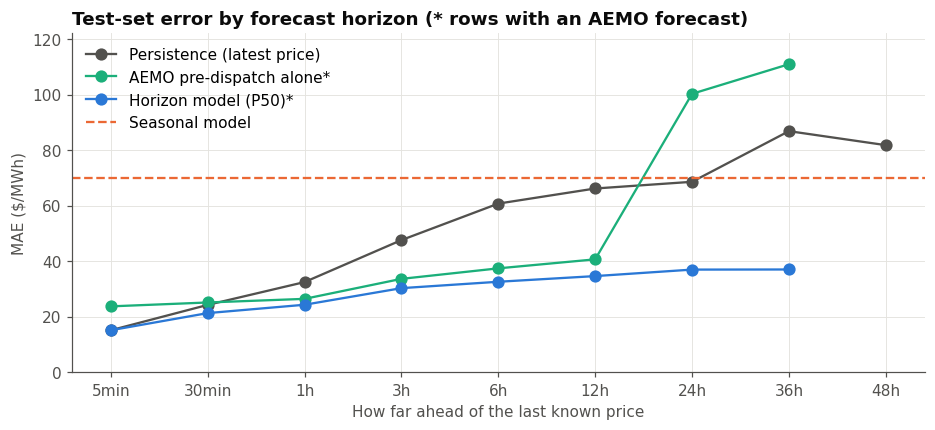

In [11]:
# CHART — how error grows as you forecast further ahead, for each method.

x = np.arange(len(by_horizon))
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, by_horizon["Persistence MAE"], marker="o", markersize=7, color=MUTED, label="Persistence (latest price)")
ax.plot(x, by_horizon["AEMO MAE*"], marker="o", markersize=7, color=SERIES[2], label="AEMO pre-dispatch alone*")
ax.plot(x, by_horizon["Model MAE*"], marker="o", markersize=7, color=SERIES[0], label="Horizon model (P50)*")
ax.axhline(seasonal_mae["MAE"], color=SERIES[1], linestyle="--", linewidth=1.5, label="Seasonal model")
ax.set_xticks(x, by_horizon.index); ax.set_xlabel("How far ahead of the last known price")
ax.set_ylim(0, min(150, np.nanmax(by_horizon[["Persistence MAE", "AEMO MAE*"]].values) * 1.1))
ax.set_ylabel("MAE ($/MWh)")
ax.set_title("Test-set error by forecast horizon (* rows with an AEMO forecast)")
ax.legend(loc="upper left")
plt.show()

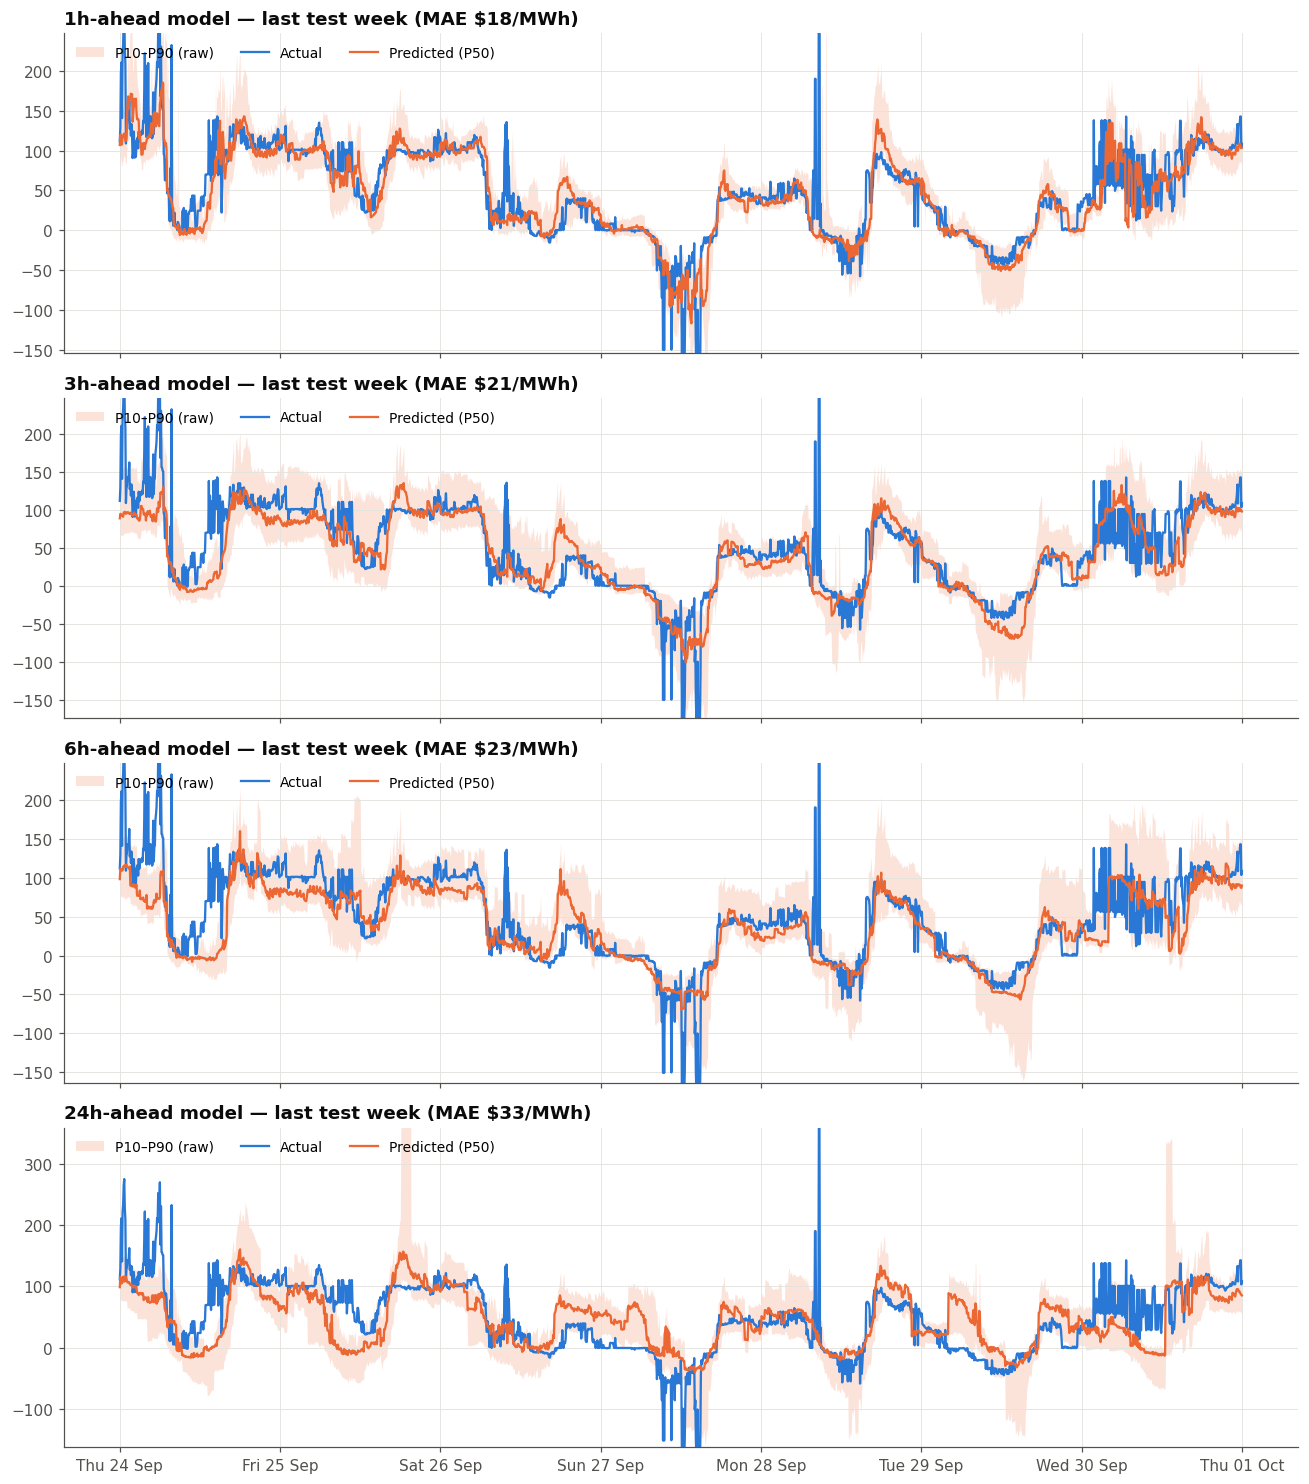

In [12]:
# CHART — one week of the test period: actual price vs the 1 h, 3 h, 6 h and 24 h-ahead forecasts,
# each with its P10–P90 band. Shows how the forecast loosens its grip on the actual price as the horizon grows.

wk_start = y_te.index.max().normalize() - pd.Timedelta(days=7)
w = slice(wk_start, wk_start + pd.Timedelta(days=7))
WEEK_HORIZONS = ["1h", "3h", "6h", "24h"]
fig, axes = plt.subplots(len(WEEK_HORIZONS), 1, figsize=(12, 3.4 * len(WEEK_HORIZONS)), sharex=True)
for ax, name in zip(axes, WEEK_HORIZONS):
    q = te_pred[name].loc[w]
    mae = (q["y"] - q["p50"]).abs().mean()
    ax.fill_between(q.index, q["p10"], q["p90"], color=SERIES[1], alpha=0.18, linewidth=0, label="P10–P90 (raw)")
    ax.plot(q.index, q["y"], color=SERIES[0], label="Actual")
    ax.plot(q.index, q["p50"], color=SERIES[1], label="Predicted (P50)")
    ax.set_title(f"{name}-ahead model — last test week (MAE ${mae:.0f}/MWh)")
    ax.legend(loc="upper left", ncol=3, fontsize=9)
    lo = min(np.nanpercentile(q["y"], 1), np.nanpercentile(q["p10"], 1))
    hi = max(np.nanpercentile(q["y"], 99.5), np.nanpercentile(q["p90"], 99))
    ax.set_ylim(lo - 20, hi + 20)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.tight_layout()
plt.show()

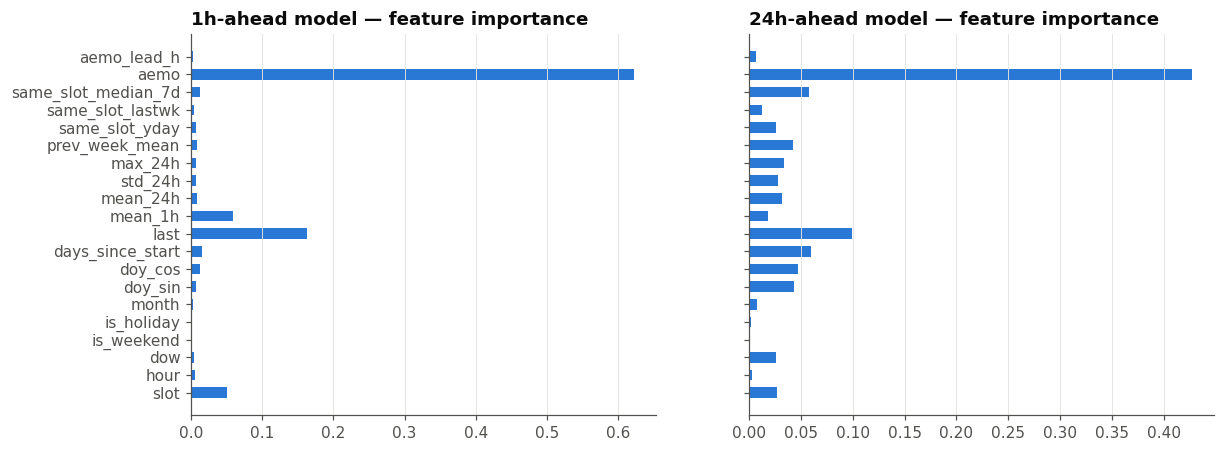

In [13]:
# CHART — which inputs each model relies on most (share of LightGBM split gain).

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, name in zip(axes, ["1h", "24h"]):
    imp = pd.Series(horizon_models[name]["p50"].booster_.feature_importance("gain"), index=FEATURES)
    imp = imp / imp.sum()
    ax.barh(imp.index, imp, color=SERIES[0], height=0.6)
    ax.set_title(f"{name}-ahead model — feature importance")
    ax.grid(axis="y", visible=False); ax.invert_yaxis()
plt.show()

### Does it pick the right times to buy and sell?

For a solar + battery household the exact price matters less than **when** the cheap and expensive periods fall. For every test day this picks the cheapest and the most expensive 2-hour window according to each forecast, then looks at what the price **actually** was in that window:

* **Capture** = how much of the best possible saving the forecast achieved, versus simply buying/selling at the day's average price. 100% = it found the actual best window; 0% = no better than random timing.

Expensive periods are driven by price spikes, which the median (P50) smooths away — so for selling, ranking windows by an upper quantile, or by AEMO's own pre-dispatch forecast (which does forecast spike timing, if noisily), can work better. The cell below tests these for each side and `plan_next()` uses whichever captured the most across the 6–48 h horizons.

In [14]:
# DECISION TEST — does the forecast pick the right times to buy and sell?
# For every test day: choose the cheapest / most expensive 2-hour window by the forecast, then check the ACTUAL
# price there. "Capture" = share of the best possible saving achieved versus trading at the day's average price.
# It also tries several ranking rules and stores the best ones as BUY_RANK / SELL_RANK for plan_next().

WINDOW = 24       # 2 hours of 5-minute intervals

def window_capture(y, f, f_sell=None):
    # per day: actual price in the forecast's best window vs the true best window and the daily average
    f_sell = f if f_sell is None else f_sell
    out = []
    for day, g in pd.DataFrame({"y": y, "f": f, "fs": f_sell}).dropna().groupby(lambda t: (t - STEP).date()):
        if len(g) < PER_DAY - 12:
            continue
        ry, rf, rs = (g[c].rolling(WINDOW).mean() for c in ["y", "f", "fs"])
        avg = g["y"].mean()
        out.append({"buy_gain": avg - ry[rf.idxmin()], "buy_best": avg - ry.min(),
                    "sell_gain": ry[rs.idxmax()] - avg, "sell_best": ry.max() - avg})
    o = pd.DataFrame(out, columns=["buy_gain", "buy_best", "sell_gain", "sell_best"])
    return {"Buy: capture": o.buy_gain.sum() / o.buy_best.sum(),
            "Buy: $/MWh below day avg": o.buy_gain.mean(),
            "Sell: capture": o.sell_gain.sum() / o.sell_best.sum(),
            "Sell: $/MWh above day avg": o.sell_gain.mean(), "days": len(o)}

def rank_series(q, how):
    aemo = q["aemo"].fillna(q["p50"])          # AEMO's forecast where a run covers it, else the model
    return {"p10": q["p10"], "p50": q["p50"], "p90": q["p90"],
            "p10-p50 mid": (q["p10"] + q["p50"]) / 2, "p50-p90 mid": (q["p50"] + q["p90"]) / 2,
            "aemo": aemo, "aemo-p50 mid": (aemo + q["p50"]) / 2}[how]

LONG = ["6h", "12h", "24h", "36h", "48h"]
buy_scores = {how: np.mean([window_capture(te_pred[n]["y"], rank_series(te_pred[n], how))["Buy: capture"] for n in LONG])
              for how in ["p10", "p10-p50 mid", "p50", "aemo", "aemo-p50 mid"]}
sell_scores = {how: np.mean([window_capture(te_pred[n]["y"], te_pred[n]["p50"], rank_series(te_pred[n], how))["Sell: capture"]
                             for n in LONG]) for how in ["p50", "p50-p90 mid", "p90", "aemo", "aemo-p50 mid"]}
BUY_RANK, SELL_RANK = max(buy_scores, key=buy_scores.get), max(sell_scores, key=sell_scores.get)
print("Average buy capture by ranking: ", {k: f"{v:.0%}" for k, v in buy_scores.items()}, "→ using", BUY_RANK)
print("Average sell capture by ranking:", {k: f"{v:.0%}" for k, v in sell_scores.items()}, "→ using", SELL_RANK)

decision = pd.DataFrame({
    **{f"{n}-ahead model": window_capture(te_pred[n]["y"], rank_series(te_pred[n], BUY_RANK),
                                          rank_series(te_pred[n], SELL_RANK)) for n in ["1h", "6h", "24h", "48h"]},
    "AEMO alone (6h-ahead)": window_capture(te_pred["6h"]["y"], te_pred["6h"]["aemo"]),
    "Seasonal model": window_capture(y_te, te_seasonal["p50"]),
}).T
decision.style.format({"Buy: capture": "{:.0%}", "Sell: capture": "{:.0%}", "days": "{:.0f}",
                       "Buy: $/MWh below day avg": "{:.1f}", "Sell: $/MWh above day avg": "{:.1f}"})

Average buy capture by ranking:  {'p10': '64%', 'p10-p50 mid': '66%', 'p50': '68%', 'aemo': '65%', 'aemo-p50 mid': '66%'} → using p50
Average sell capture by ranking: {'p50': '23%', 'p50-p90 mid': '18%', 'p90': '17%', 'aemo': '25%', 'aemo-p50 mid': '27%'} → using aemo-p50 mid


,Buy: capture,Buy: $/MWh below day avg,Sell: capture,Sell: $/MWh above day avg,days
1h-ahead model,87%,54.3,86%,117.5,183
6h-ahead model,73%,45.6,42%,56.8,183
24h-ahead model,66%,41.3,20%,27.1,183
48h-ahead model,61%,38.1,24%,32.3,183
AEMO alone (6h-ahead),69%,43.1,40%,54.8,183
Seasonal model,60%,37.9,26%,35.7,183


### Calibrating the P10–P90 band

Raw quantile models are over-confident here: fewer actual prices land inside their P10–P90 band than the 80% it should hold. **Conformalised quantile regression** fixes this by widening each model's band by a fixed amount learned on out-of-sample data. To check it honestly, the widening is learned on the first half of the test period and evaluated on the second half; the production adjustment then uses the whole test period.

In [15]:
# CALIBRATION — widen or narrow each model's P10–P90 band so that 80% of actual prices fall inside it.
# Learned on the first half of the test period, checked on the second half; BAND_ADJ is used in every forecast.

def conformal_adj(y, q, coverage=0.8):
    # how much to widen [p10, p90] so `coverage` of y falls inside
    score = np.maximum(q["p10"] - y, y - q["p90"])
    n = len(score)
    return float(np.quantile(score, min(1, np.ceil((n + 1) * coverage) / n)))

def coverage(y, lo, hi):
    return ((y >= lo) & (y <= hi)).mean()

BAND_ADJ, rows = {}, []
for name, q in [*te_pred.items(), ("seasonal", te_seasonal.assign(y=y_te))]:
    half = q.index[len(q) // 2]
    cal_, chk = q[q.index <= half], q[q.index > half]
    adj = conformal_adj(cal_["y"], cal_)
    rows.append({"model": name, "widen by ±$": adj,
                 "coverage before": coverage(chk["y"], chk["p10"], chk["p90"]),
                 "coverage after": coverage(chk["y"], chk["p10"] - adj, chk["p90"] + adj)})
    BAND_ADJ[name] = conformal_adj(q["y"], q)        # production value, from the full test period
calib = pd.DataFrame(rows).set_index("model")
calib.style.format({"widen by ±$": "{:.1f}", "coverage before": "{:.1%}", "coverage after": "{:.1%}"})

,widen by ±$,coverage before,coverage after
model,,,
5min,-1.2,86.2%,82.5%
30min,-3.1,88.0%,80.6%
1h,-1.7,86.3%,83.6%
3h,-0.9,84.4%,83.4%
6h,0.7,81.0%,81.8%
12h,2.4,84.2%,86.7%
24h,11.6,72.2%,83.6%
36h,34.9,65.3%,87.6%
48h,43.7,56.0%,83.6%


## 7. Refit on all history

Evaluation is done, so the production models are retrained on the full history (including the test months) to use the most recent behaviour.

In [16]:
%%time
# REFIT — retrains every model on ALL the history, test months included, so live forecasts use the
# most recent behaviour (~5 min). `frames` is deleted afterwards to free memory.

seasonal_models = fit_quantiles(cal_all, price)
for name, f in frames.items():
    f = f.dropna(subset=PRICE_COLS + ["y"])
    horizon_models[name] = fit_quantiles(f[FEATURES], f["y"])
del frames
print("Models refit on", f"{len(price):,}", "intervals")

Models refit on 525,888 intervals
CPU times: user 10min 9s, sys: 6min 43s, total: 16min 53s
Wall time: 4min 49s


## 8. Live data

**Prices — OpenElectricity API.** `get_live_prices()` pulls 5-minute SA1 prices for a date range in ≤ 7-day chunks (as the API docs recommend) and normalises them to the same convention as the AEMO history (NEM time, interval-ending). `align_check()` fetches a day that overlaps the AEMO history and picks the timestamp shift that makes the two sources agree. (Checked Oct 2026: the API already uses AEMO's interval-ending convention, so the shift is 0 and prices match exactly.)

**AEMO pre-dispatch — NEMWeb.** AEMO keeps the last ~14 days of pre-dispatch runs at `nemweb.com.au/Reports/Current/PredispatchIS_Reports/` (public, no key). `update_live_predispatch()` downloads runs that aren't cached yet and appends their SA1 rows to `data/sa1_predispatch_live.csv`.

In [17]:
# LIVE PRICES (OpenElectricity API)
#   get_live_prices(start, end): 5-minute SA1 prices for any recent period, fetched in ≤ 7-day chunks
#   align_check(): confirms the API's timestamps line up exactly with AEMO's history

from openelectricity import OEClient
from openelectricity.types import MarketMetric
import logging
for _h in [logging.getLogger("openelectricity"), *logging.getLogger("openelectricity").handlers]:
    _h.setLevel(logging.WARNING)      # silence the SDK's DEBUG request logs

API_KEY = os.getenv("OPENELECTRICITY_API_KEY")
LIVE_OK = bool(API_KEY)
OE_SHIFT = pd.Timedelta(0)   # API timestamps already match AEMO's interval-end convention; align_check() confirms
_live_cache = pd.Series(dtype=float)

def _to_nem_naive(ts: pd.Series) -> pd.DatetimeIndex:
    idx = pd.DatetimeIndex(pd.to_datetime(ts))
    if idx.tz is not None:
        idx = idx.tz_convert(NEM_TZ).tz_localize(None)
    return idx

def get_live_prices(start, end, shift=None) -> pd.Series:
    # 5-minute SA1 prices from OpenElectricity, NEM time, interval-ending
    if not LIVE_OK:
        raise RuntimeError("No OPENELECTRICITY_API_KEY set — add it to .env to use live data.")
    shift = OE_SHIFT if shift is None else shift
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    chunks = []
    with OEClient(api_key=API_KEY) as client:
        t = start
        while t < end:
            t_end = min(t + pd.Timedelta(days=7), end)
            resp = client.get_market(network_code="NEM", metrics=[MarketMetric.PRICE], interval="5m",
                                     date_start=t.to_pydatetime(), date_end=t_end.to_pydatetime(),
                                     primary_grouping="network_region", network_region=REGION)
            df = resp.to_pandas()
            if len(df):
                region_col = next((c for c in df.columns if "region" in c.lower()), None)
                if region_col:
                    df = df[df[region_col].astype(str).str.upper() == REGION]
                chunks.append(pd.Series(df["price"].astype(float).values,
                                        index=_to_nem_naive(df["interval"]) + shift))
            t = t_end
    if not chunks:
        return pd.Series(dtype=float)
    s = pd.concat(chunks).sort_index()
    return s[~s.index.duplicated(keep="last")]

def align_check():
    # Compare a day of API data with AEMO history and keep the shift that matches best
    global OE_SHIFT
    day_end = price.index.max().normalize()
    api = get_live_prices(day_end - pd.Timedelta(days=1), day_end, shift=pd.Timedelta(0))
    diffs = {}
    for sh in [-STEP, pd.Timedelta(0), STEP]:
        a = api.copy(); a.index = a.index + sh
        both = pd.concat([a.rename("api"), price.rename("aemo")], axis=1, join="inner").dropna()
        diffs[sh] = (both.api - both.aemo).abs()
        print(f"shift {int(sh.total_seconds() // 60):+d} min: {len(both)} intervals, "
              f"{(diffs[sh] < 0.01).mean():.1%} exact, mean abs diff ${diffs[sh].mean():.2f}")
    OE_SHIFT = min(diffs, key=lambda k: diffs[k].mean())
    print(f"Using shift {OE_SHIFT}")

if LIVE_OK:
    align_check()
else:
    print("OPENELECTRICITY_API_KEY not set — live price sections will be skipped.")

shift -5 min: 288 intervals, 15.3% exact, mean abs diff $17.36
shift +0 min: 288 intervals, 100.0% exact, mean abs diff $0.00
shift +5 min: 288 intervals, 15.6% exact, mean abs diff $17.36
Using shift 0 days 00:00:00


In [18]:
# LIVE AEMO FORECASTS (NEMWeb, public, no key)
#   update_live_predispatch(): downloads new pre-dispatch runs and caches the SA1 rows in data/sa1_predispatch_live.csv
#   predispatch_all(): archive + live runs combined — what the forecasting functions look up

import io, re, zipfile, csv, urllib.request

PD_CURRENT = "https://nemweb.com.au/Reports/Current/PredispatchIS_Reports/"
PD_LIVE_CSV = DATA / "sa1_predispatch_live.csv"
_pd_checked = pd.Timestamp(0)

def _parse_predispatch(raw: bytes) -> pd.DataFrame:
    rows = []
    with zipfile.ZipFile(io.BytesIO(raw)) as zf:
        for name in zf.namelist():
            header = None
            for rec in csv.reader(io.TextIOWrapper(zf.open(name), encoding="utf-8")):
                if rec[:3] == ["I", "PREDISPATCH", "REGION_PRICES"]:
                    header = rec
                elif rec[:3] == ["D", "PREDISPATCH", "REGION_PRICES"] and header:
                    r = dict(zip(header, rec))
                    if r["REGIONID"] == REGION and r["INTERVENTION"] == "0":
                        rows.append((r["LASTCHANGED"], r["DATETIME"], float(r["RRP"])))
    return pd.DataFrame(rows, columns=["ISSUED", "PERIOD_END", "RRP"])

def update_live_predispatch(since=None, every=1) -> pd.DataFrame:
    # Download pre-dispatch runs published since `since` (default: last 2 h) that aren't cached yet;
    # every=2 takes every second run (hourly) to save bandwidth for backfills
    global _pd_checked
    since = pd.Timestamp(since) if since is not None else pd.Timestamp.now(tz=NEM_TZ).tz_localize(None) - pd.Timedelta("2h")
    cache = (pd.read_csv(PD_LIVE_CSV, parse_dates=["ISSUED", "PERIOD_END"]) if PD_LIVE_CSV.exists()
             else pd.DataFrame(columns=["ISSUED", "PERIOD_END", "RRP", "FILE"]))
    listing = urllib.request.urlopen(PD_CURRENT, timeout=30).read().decode()
    files = sorted(set(re.findall(r"PUBLIC_PREDISPATCHIS_(\d{12})_(\d{14})\.zip", listing)))
    files = [(run, pub) for run, pub in files if pd.Timestamp(run) >= since][::-1][::every]
    have = set(cache["FILE"].astype(str))
    new = []
    for run, pub in files:
        fname = f"PUBLIC_PREDISPATCHIS_{run}_{pub}.zip"
        if fname not in have:
            raw = urllib.request.urlopen(PD_CURRENT + fname, timeout=60).read()
            new.append(_parse_predispatch(raw).assign(FILE=fname))
    if new:
        add = pd.concat(new)
        add["ISSUED"], add["PERIOD_END"] = pd.to_datetime(add["ISSUED"]), pd.to_datetime(add["PERIOD_END"])
        cache = pd.concat([cache, add], ignore_index=True)
        cache.to_csv(PD_LIVE_CSV, index=False)
    _pd_checked = pd.Timestamp.now()
    return cache

def predispatch_all() -> pd.DataFrame:
    # archive + live runs, refreshed at most every 5 minutes
    global _pd_all
    if "_pd_all" not in globals() or pd.Timestamp.now() - _pd_checked > STEP:
        try:
            live = update_live_predispatch()
        except Exception as exc:
            print(f"(AEMO pre-dispatch unavailable: {exc})")
            live = pd.read_csv(PD_LIVE_CSV, parse_dates=["ISSUED", "PERIOD_END"]) if PD_LIVE_CSV.exists() else None
        parts = [pd_hist] + ([live[["ISSUED", "PERIOD_END", "RRP"]]] if live is not None and len(live) else [])
        _pd_all = pd.concat(parts).drop_duplicates(["ISSUED", "PERIOD_END"])
    return _pd_all

pdp_live = predispatch_all()
latest_run = pdp_live["ISSUED"].max()
run = pdp_live[pdp_live["ISSUED"] == latest_run]
print(f"Latest AEMO pre-dispatch run: published {latest_run}, covers {run['PERIOD_END'].min()} → {run['PERIOD_END'].max()}")

Latest AEMO pre-dispatch run: published 2026-11-12 22:01:25, covers 2026-11-12 22:30:00 → 2026-11-14 04:00:00


Live data: 2026-09-30 00:00:00 → 2026-11-12 22:30:00 (12,655 intervals)
Current price: {'interval_end_nem': Timestamp('2026-11-12 22:30:00'), 'price': 145.22, 'c_per_kWh': 14.52, 'source': 'OpenElectricity API'}


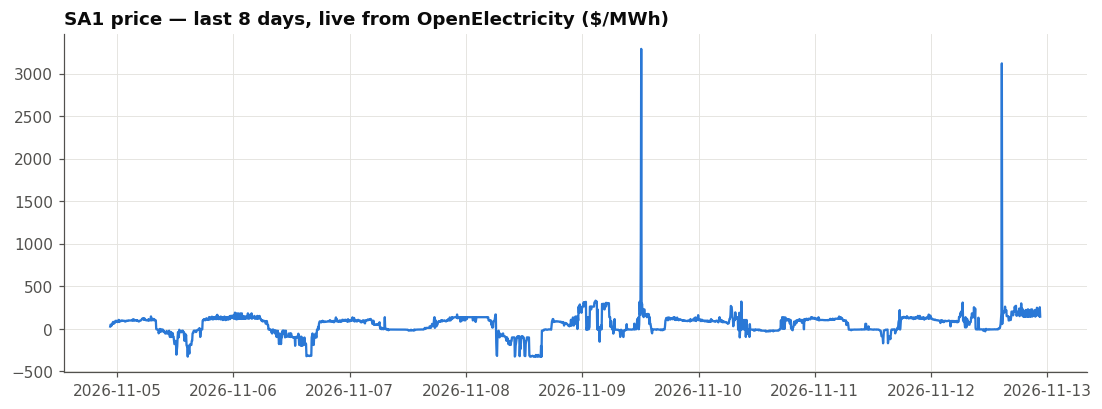

In [19]:
# RECENT PRICES + CURRENT PRICE
#   recent_prices(): live prices from the end of the AEMO history up to now (cached for 5 minutes)
#   current_price(): the latest published SA1 price in $/MWh and c/kWh
# Also plots the last 8 days.

def recent_prices(max_days=60) -> pd.Series:
    # Live prices from the end of the AEMO history up to now (≤ max_days), cached for 5 minutes
    global _live_cache
    now = pd.Timestamp.now(tz=NEM_TZ).tz_localize(None)
    if len(_live_cache) == 0 or now - _live_cache.attrs.get("fetched", pd.Timestamp(0)) > STEP:
        start = max(price.index.max() - pd.Timedelta(days=1), now - pd.Timedelta(days=max_days))
        _live_cache = get_live_prices(start, now + STEP)
        _live_cache.attrs["fetched"] = now
    return _live_cache

def current_price() -> dict:
    # The latest published SA1 price
    live = recent_prices()
    return {"interval_end_nem": live.index[-1], "price": round(float(live.iloc[-1]), 2),
            "c_per_kWh": round(float(live.iloc[-1]) / 10, 2), "source": "OpenElectricity API"}

if LIVE_OK:
    live = recent_prices()
    print(f"Live data: {live.index.min()} → {live.index.max()} ({len(live):,} intervals)")
    print("Current price:", current_price())
    last8 = live[live.index > live.index.max() - pd.Timedelta(days=8)]
    fig, ax = plt.subplots()
    ax.plot(last8.index, last8, color=SERIES[0])
    ax.set_title("SA1 price — last 8 days, live from OpenElectricity ($/MWh)")
    plt.show()

## 9. Ask for a price at any time

`price_at(when)` returns the **predicted** and **actual** price for the 5-minute interval containing `when`:

* **Prediction** — made *as of* the latest known price (AEMO history + live API), using AEMO's latest pre-dispatch run. The gap between the last known price and `when` picks the horizon model (5 min … 48 h); beyond 48 h the seasonal model is used. Includes the calibrated P10–P90 band (80% of actual prices should fall inside it) and AEMO's own forecast for comparison.
* **Actual** — from the AEMO history CSV if available, else from the OpenElectricity API, else `None` (future).

For a time that has **already happened**, there's no single "right" horizon, so by default you get the forecast that would have been made 24 h earlier. Pass `as_of=` to choose — e.g. `price_at(t, as_of=t - pd.Timedelta("1h"))` gives the 1 h-ahead forecast.

`when` (and `as_of`) are NEM time by default; pass `tz="Australia/Adelaide"` (or any tz) to give local time instead. Prices are $/MWh; divide by 10 for c/kWh.

In [20]:
# THE MAIN QUERY FUNCTIONS
#   forecast(targets, as_of): forecasts many intervals at once from one point in time; each target automatically
#                             uses the horizon model that matches its distance from the last known price
#   price_at(when):           predicted vs actual price for one time (actual from history, the live API, or None)
#   compare(times):           price_at() for a list of times, as a table
# Helpers: _to_nem (time-zone conversion), _known_series (history + live prices), _actual (looks up the real price).

def _to_nem(when, tz=None) -> pd.Timestamp:
    t = pd.Timestamp(when)
    if tz is not None and t.tz is None:
        t = t.tz_localize(tz)
    if t.tz is not None:
        t = t.tz_convert(NEM_TZ).tz_localize(None)
    return t

def _known_series() -> pd.Series:
    # AEMO history stitched with live API data
    s = price
    if LIVE_OK:
        try:
            live = recent_prices()
            s = pd.concat([s, live[live.index > s.index.max()]])
        except Exception as exc:
            print(f"(live data unavailable: {exc})")
    return s

def _grid(s: pd.Series, start, end) -> pd.Series:
    # continuous 5-minute grid; only short interior gaps are filled
    return s.reindex(pd.date_range(start, end, freq=STEP)).interpolate(limit=6, limit_area="inside")

def _actual(t: pd.Timestamp):
    if t in price.index and not np.isnan(price.loc[t]):
        return float(price.loc[t]), "AEMO history (nemosis)"
    if LIVE_OK:
        try:
            live = recent_prices()
            s = live if t >= live.index.min() else get_live_prices(t - pd.Timedelta(hours=1), t + STEP)
            if t in s.index:
                return float(s.loc[t]), "OpenElectricity API"
        except Exception as exc:
            return None, f"live lookup failed: {exc}"
    return None, "not available yet" if t > pd.Timestamp.now(tz=NEM_TZ).tz_localize(None) else "not available"

def pick_horizon(gap: pd.Timedelta):
    # shortest horizon model that covers the gap, or None if beyond the longest
    steps = int(np.ceil(gap / STEP))
    return next((name for name, k in HORIZONS.items() if k >= steps), None)

def forecast(targets: pd.DatetimeIndex, as_of=None) -> pd.DataFrame:
    # Forecast every target interval from one point in time (`as_of`, default: latest known price).
    # Each target uses the horizon model matching its own gap; AEMO's run published by then is an input.
    known = _known_series()
    last_known = known.index.max()
    as_of = last_known if as_of is None else min(pd.Timestamp(as_of).floor("5min"), last_known)
    targets = pd.DatetimeIndex(targets)
    live_mode = as_of == last_known
    pd_cutoff = pd.Timestamp.now(tz=NEM_TZ).tz_localize(None) if live_mode else as_of
    grid = _grid(known[known.index <= as_of], min(targets.min(), as_of) - pd.Timedelta(days=10), targets.max())
    feats = calendar_features(targets).join(aemo_features(targets, pd_cutoff, predispatch_all()))
    gaps = pd.Series([pick_horizon(t - as_of) if t > as_of else None for t in targets], index=targets)
    out = []
    for name, idx in gaps.dropna().groupby(gaps.dropna()).groups.items():
        X = feats.loc[idx].join(price_features(grid, HORIZONS[name]).reindex(idx))
        ok = X[PRICE_COLS].notna().all(axis=1)
        if ok.any():
            q = horizon_predict(name, X[ok])
            out.append(q.assign(p10=q["p10"] - BAND_ADJ[name], p90=q["p90"] + BAND_ADJ[name], model=f"{name}-ahead"))
    done = pd.concat(out).index if out else pd.DatetimeIndex([])
    rest = targets.difference(done)
    if len(rest):
        q = predict_quantiles(seasonal_models, feats.loc[rest, CAL_FEATURES])
        out.append(q.assign(p10=q["p10"] - BAND_ADJ["seasonal"], p90=q["p90"] + BAND_ADJ["seasonal"], model="seasonal"))
    res = pd.concat(out).reindex(targets)
    res["aemo"] = feats["aemo"]
    res["forecast_as_of"] = as_of
    return res

def price_at(when, tz=None, as_of=None) -> dict:
    # interval-ending timestamp of the 5-minute interval containing `when`
    # (18:30 exactly belongs to 18:30–18:35, which AEMO labels 18:35)
    t = _to_nem(when, tz).floor("5min") + STEP
    last_known = _known_series().index.max()
    if as_of is None:
        as_of = last_known if t > last_known else t - pd.Timedelta(days=1)
    else:
        as_of = _to_nem(as_of, tz)
    as_of = min(as_of.floor("5min"), last_known, t - STEP)
    f = forecast(pd.DatetimeIndex([t]), as_of).iloc[0]
    actual, source = _actual(t)
    return {
        "interval_end_nem": t,
        "forecast_as_of": f["forecast_as_of"],
        "model": f["model"],
        "predicted_p50": round(float(f["p50"]), 2),
        "predicted_p10": round(float(f["p10"]), 2),
        "predicted_p90": round(float(f["p90"]), 2),
        "aemo_forecast": None if pd.isna(f["aemo"]) else round(float(f["aemo"]), 2),
        "actual": None if actual is None else round(actual, 2),
        "actual_source": source,
        "error": None if actual is None else round(actual - float(f["p50"]), 2),
    }

def compare(times, tz=None, as_of=None) -> pd.DataFrame:
    return pd.DataFrame([price_at(t, tz, as_of) for t in times]).set_index("interval_end_nem")

In [21]:
# EXAMPLES — the current price, then forecasts for 5 min, 1 h, 6 h, tomorrow evening, in two days and next month.
# The "model" column shows which horizon model was used.

# Examples: the current price, then forecasts from the latest known price out to next month
if LIVE_OK:
    print("Current price:", current_price())
now_nem = pd.Timestamp.now(tz=NEM_TZ).tz_localize(None).floor("min")
examples = [
    now_nem + pd.Timedelta(minutes=5),                                    # next interval
    now_nem + pd.Timedelta(hours=1),                                      # 1 h ahead
    now_nem + pd.Timedelta(hours=6),                                      # 6 h ahead
    (now_nem + pd.Timedelta(days=1)).replace(hour=18, minute=30),         # tomorrow evening peak
    (now_nem + pd.Timedelta(days=2)).replace(hour=13, minute=0),          # midday in two days
    (now_nem + pd.Timedelta(days=30)).replace(hour=13, minute=0),         # midday next month
]
compare(examples)

Current price: {'interval_end_nem': Timestamp('2026-11-12 22:30:00'), 'price': 145.22, 'c_per_kWh': 14.52, 'source': 'OpenElectricity API'}


,forecast_as_of,model,predicted_p50,predicted_p10,predicted_p90,aemo_forecast,actual,actual_source,error
interval_end_nem,,,,,,,,,
2026-11-12 22:40:00,2026-11-12 22:30:00,30min-ahead,147.67,135.89,184.16,146.79,None,not available yet,None
2026-11-12 23:35:00,2026-11-12 22:30:00,3h-ahead,138.47,111.37,251.86,151.57,None,not available yet,None
2026-11-13 04:35:00,2026-11-12 22:30:00,12h-ahead,153.80,115.16,673.97,672.01,None,not available yet,None
2026-11-13 18:35:00,2026-11-12 22:30:00,24h-ahead,194.86,69.33,1652.97,1001.00,None,not available yet,None
2026-11-14 13:05:00,2026-11-12 22:30:00,48h-ahead,-0.31,-107.22,45.72,NaN,None,not available yet,None
2026-12-12 13:05:00,2026-11-12 22:30:00,seasonal,-27.00,-121.59,86.87,NaN,None,not available yet,None


In [22]:
# BACK-TEST EXAMPLE — the same past interval forecast from 24 h, 6 h, 1 h and 5 min beforehand (via as_of=),
# showing the forecast getting closer to the actual price as the horizon shrinks.

# A past time: the same interval forecast from 24 h, 6 h and 1 h before
t_past = price.index.max() - pd.Timedelta(days=30) + pd.Timedelta(hours=18)
pd.DataFrame([price_at(t_past, as_of=t_past - pd.Timedelta(h)) for h in ["24h", "6h", "1h", "5min"]]) \
  .set_index("model")

,interval_end_nem,forecast_as_of,predicted_p50,predicted_p10,predicted_p90,aemo_forecast,actual,actual_source,error
model,,,,,,,,,
36h-ahead,2026-09-01 18:05:00,2026-08-31 18:00:00,62.74,11.67,128.12,30.15,51.29,AEMO history (nemosis),-11.44
12h-ahead,2026-09-01 18:05:00,2026-09-01 12:00:00,67.31,29.28,112.18,55.90,51.29,AEMO history (nemosis),-16.01
3h-ahead,2026-09-01 18:05:00,2026-09-01 17:00:00,95.53,75.51,116.57,105.08,51.29,AEMO history (nemosis),-44.24
30min-ahead,2026-09-01 18:05:00,2026-09-01 17:55:00,58.33,36.92,77.62,48.71,51.29,AEMO history (nemosis),-7.04


In [23]:
# YOUR TURN — change the time below. NEM time by default; tz="Australia/Adelaide" lets you type local time.

# Try your own — NEM time by default, or pass tz="Australia/Adelaide"
price_at("2026-10-23 18:30", tz="Australia/Adelaide")

{'interval_end_nem': Timestamp('2026-10-23 18:05:00'),
 'forecast_as_of': Timestamp('2026-10-22 18:05:00'),
 'model': '24h-ahead',
 'predicted_p50': 105.24,
 'predicted_p10': -12.48,
 'predicted_p90': 154.3,
 'aemo_forecast': None,
 'actual': 144.41,
 'actual_source': 'OpenElectricity API',
 'error': 39.17}

## 10. When should I buy and when should I export?

`plan_next(hours=48)` forecasts every 5-minute interval from now to `hours` ahead and lists:

* **Cheapest windows** — best times to charge a battery, run the EV charger / hot water / pool pump, or import from the grid.
* **Most expensive windows** — best times to export from a battery (or avoid using grid power).
* **Negative-price periods** — on a wholesale pass-through plan you *pay* to export then, so curtail exports and soak up power instead.

Windows are ranked using whichever quantile picked the best windows in the test-set evaluation (section 6: `BUY_RANK`, `SELL_RANK`). The P10/P90 columns show the risk: a buy window whose P90 is still low, or a sell window whose P10 is still high, is a confident call.

> These are **wholesale** prices. They only flow through to your bill on a pass-through retailer (e.g. Amber) or a VPP — network charges, fees and GST are added on top. On a standard fixed time-of-use plan with a fixed feed-in tariff, wholesale prices don't change what you pay or earn.

Forecast made from the price at 2026-11-12 22:30:00 NEM time — next 48 h, times shown in Australia/Adelaide

Cheapest 2h windows (charge / import):


,from,to,P50 $/MWh,P10,P90,P50 c/kWh
0,2026-11-14 08:30:00,2026-11-14 10:30:00,-8.0,-53.4,60.3,-0.8
1,2026-11-14 10:30:00,2026-11-14 12:30:00,-3.6,-85.9,57.5,-0.4
2,2026-11-14 14:30:00,2026-11-14 16:30:00,-9.0,-109.3,66.2,-0.9


Most expensive 2h windows (export / avoid grid):


,from,to,P50 $/MWh,P10,P90,P50 c/kWh
0,2026-11-13 19:30:00,2026-11-13 21:30:00,161.2,73.4,1394.4,16.1
1,2026-11-13 22:00:00,2026-11-14 00:00:00,118.5,51.3,801.5,11.9
2,2026-11-14 00:00:00,2026-11-14 02:00:00,84.3,15.3,168.8,8.4


Expected negative prices (don't export; use or store power):


,from,to
0,2026-11-14 08:00:00,2026-11-14 13:00:00
1,2026-11-14 13:30:00,2026-11-14 16:30:00


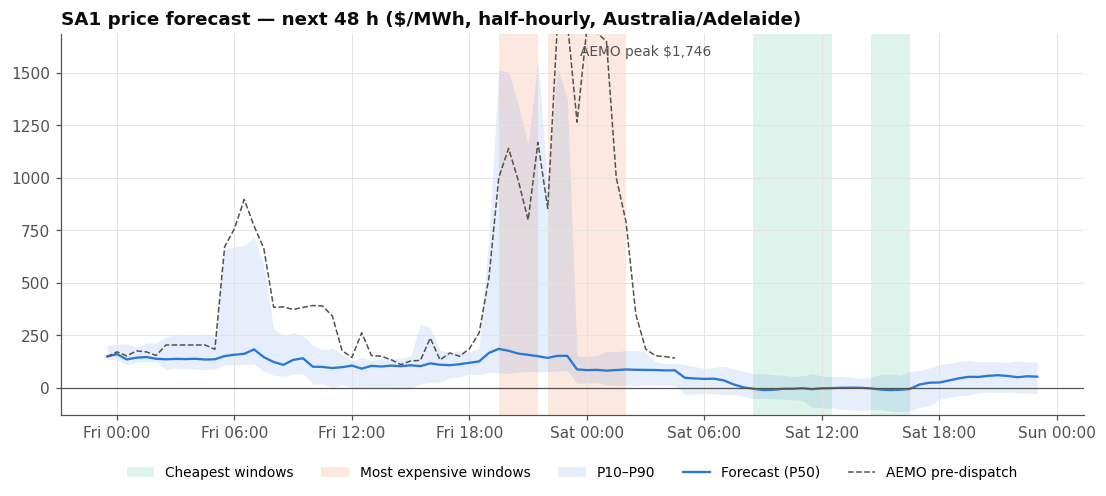

In [24]:
# BUY / EXPORT PLANNER — plan_next(hours, window, n, tz)
#   1. forecasts every 5-minute interval for the next `hours`
#   2. averages to half-hours
#   3. finds the n cheapest and n most expensive non-overlapping windows of length `window`
#   4. lists periods where prices are expected to be negative
# Prints the tables and draws the chart; also returns them as a dict for further use.

def _top_windows(s: pd.Series, n_slots: int, n: int, cheapest: bool):
    # n non-overlapping windows of n_slots consecutive half-hours, by mean of s
    roll = s.rolling(n_slots).mean().dropna()
    roll = roll.sort_values(ascending=cheapest)
    picked = []
    for end, _ in roll.items():
        start = end - pd.Timedelta(minutes=30 * n_slots)
        if all(end <= ps or start >= pe for ps, pe in picked):
            picked.append((start, end))
        if len(picked) == n:
            break
    return sorted(picked)

def plan_next(hours=48, window="2h", n=3, tz=None, show=True):
    known = _known_series()
    as_of = known.index.max()
    targets = pd.date_range(as_of + STEP, as_of + pd.Timedelta(hours=hours), freq=STEP)
    f = forecast(targets, as_of)
    hh = f[["p10", "p50", "p90", "aemo"]].resample("30min", closed="right", label="right").mean()
    n_slots = int(pd.Timedelta(window) / pd.Timedelta("30min"))

    def fmt(t):
        return t if tz is None else t.tz_localize(NEM_TZ).tz_convert(tz).tz_localize(None)

    def table(wins):
        return pd.DataFrame([{
            "from": fmt(a), "to": fmt(b),
            "P50 $/MWh": hh.loc[(hh.index > a) & (hh.index <= b), "p50"].mean(),
            "P10": hh.loc[(hh.index > a) & (hh.index <= b), "p10"].mean(),
            "P90": hh.loc[(hh.index > a) & (hh.index <= b), "p90"].mean(),
        } for a, b in wins]).assign(**{"P50 c/kWh": lambda d: d["P50 $/MWh"] / 10}).round(1)

    buy = _top_windows(rank_series(hh, BUY_RANK), n_slots, n, cheapest=True)
    sell = _top_windows(rank_series(hh, SELL_RANK), n_slots, n, cheapest=False)
    neg = hh[hh["p50"] < 0]
    neg_runs = [(g.index.min() - pd.Timedelta("30min"), g.index.max())
                for _, g in neg.groupby((neg.index.to_series().diff() != pd.Timedelta("30min")).cumsum())]

    if show:
        tzname = tz or "NEM time (AEST)"
        print(f"Forecast made from the price at {as_of} NEM time — next {hours} h, times shown in {tzname}")
        print(f"\nCheapest {window} windows (charge / import):"); display(table(buy))
        print(f"Most expensive {window} windows (export / avoid grid):"); display(table(sell))
        if neg_runs:
            print("Expected negative prices (don't export; use or store power):")
            display(pd.DataFrame([{"from": fmt(a), "to": fmt(b)} for a, b in neg_runs]))

        fig, ax = plt.subplots(figsize=(12, 4.5))
        x = [fmt(t) for t in hh.index]
        for i, (a, b) in enumerate(buy):
            ax.axvspan(fmt(a), fmt(b), color=SERIES[2], alpha=0.15, linewidth=0, label="Cheapest windows" if i == 0 else None)
        for i, (a, b) in enumerate(sell):
            ax.axvspan(fmt(a), fmt(b), color=SERIES[1], alpha=0.15, linewidth=0, label="Most expensive windows" if i == 0 else None)
        ax.fill_between(x, hh["p10"], hh["p90"], color=SERIES[0], alpha=0.12, linewidth=0, label="P10–P90")
        ax.plot(x, hh["p50"], color=SERIES[0], label="Forecast (P50)")
        if hh["aemo"].notna().any():
            ax.plot(x, hh["aemo"], color=MUTED, linewidth=1, linestyle="--", label="AEMO pre-dispatch")
        ax.axhline(0, color=MUTED, linewidth=0.8)
        lo, hi = np.nanpercentile(hh["p10"], 2), np.nanpercentile(hh["p90"], 98) * 1.1 + 20
        ax.set_ylim(min(lo, 0) - 20, hi)
        if hh["aemo"].max() > hi:            # AEMO spike forecasts would flatten the chart: clip and label
            t_pk = hh["aemo"].idxmax()
            ax.annotate(f"AEMO peak ${hh['aemo'].max():,.0f}", xy=(fmt(t_pk), hi), xytext=(8, -14),
                        textcoords="offset points", color=MUTED, fontsize=9)
        ax.set_title(f"SA1 price forecast — next {hours} h ($/MWh, half-hourly, {tzname})")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %H:%M"))
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=5, fontsize=9)
        plt.show()
    return {"half_hourly": hh, "buy": table(buy), "sell": table(sell), "negative": neg_runs}

plan = plan_next(hours=48, window="2h", tz="Australia/Adelaide")

### Which part of the day will be cheap or expensive?

`day_segments(days=2)` summarises the forecast for each part of the day in **local time** — overnight, morning, the midday solar period, the evening peak and late evening — next to what that segment *usually* costs at this time of year (median over the 5-year history). It's the quick answer to "when should I run things / export today and tomorrow?".

Only intervals still in the future are included, so the segment you're currently in covers just its remaining part.

In [25]:
# PART-OF-DAY SUMMARY — day_segments(days, tz)
# Splits the forecast into overnight / morning / midday (solar) / evening peak / late evening in LOCAL time,
# compares each with what that segment usually costs this month, and flags each day's cheapest and dearest part.

SEGMENTS = [("Overnight", 0, 6), ("Morning", 6, 9), ("Midday (solar)", 9, 16),
            ("Evening peak", 16, 21), ("Late evening", 21, 24)]

def _segment_of(hours):
    return pd.cut(hours, [s for _, s, _ in SEGMENTS] + [24], right=False, labels=[n for n, _, _ in SEGMENTS])

def _local(idx: pd.DatetimeIndex, tz) -> pd.DatetimeIndex:
    # NEM interval-end → local interval-start, so 18:00–18:05 counts as 18:00
    return (idx - STEP).tz_localize(NEM_TZ).tz_convert(tz).tz_localize(None)

def day_segments(days=2, tz="Australia/Adelaide"):
    as_of = _known_series().index.max()
    end_local = (_local(pd.DatetimeIndex([as_of + STEP]), tz)[0].normalize() + pd.Timedelta(days=days))
    end_nem = end_local.tz_localize(tz).tz_convert(NEM_TZ).tz_localize(None) + STEP
    targets = pd.date_range(as_of + STEP, end_nem - STEP, freq=STEP)
    f = forecast(targets, as_of)
    loc = _local(f.index, tz)
    f = f.assign(date=loc.date, segment=_segment_of(loc.hour))

    # typical price for each segment in this calendar month, from the history
    hist_loc = _local(price.index, tz)
    typical = price.groupby([hist_loc.month, _segment_of(hist_loc.hour)], observed=True).median()

    rows = []
    for (day, seg), g in f.groupby(["date", "segment"], observed=True):
        rows.append({"date": day, "segment": seg, "hours": len(g) / 12,
                     "forecast $/MWh": g["p50"].mean(), "c/kWh": g["p50"].mean() / 10,
                     "low (P10)": g["p10"].mean(), "high (P90)": g["p90"].mean(),
                     "typical for month": typical.get((pd.Timestamp(day).month, seg), np.nan),
                     "negative share": (g["p50"] < 0).mean()})
    out = pd.DataFrame(rows)
    # flag each day's cheapest and most expensive segment (ignoring stubs under an hour)
    out["note"] = ""
    for day, g in out[out["hours"] >= 1].groupby("date"):
        out.loc[g["forecast $/MWh"].idxmin(), "note"] = "cheapest → charge / use power"
        out.loc[g["forecast $/MWh"].idxmax(), "note"] = "most expensive → export / avoid grid"
    out.loc[(out["negative share"] >= 0.5) & (out["note"] == ""), "note"] = "mostly negative → don't export"
    return out.set_index(["date", "segment"])

segments = day_segments(days=2, tz="Australia/Adelaide")
print(f"Forecast from the price at {_known_series().index.max()} NEM time; segments in Australia/Adelaide local time")
segments.style.format({"hours": "{:.1f}", "forecast $/MWh": "{:.0f}", "c/kWh": "{:.1f}", "low (P10)": "{:.0f}",
                       "high (P90)": "{:.0f}", "typical for month": "{:.0f}", "negative share": "{:.0%}"})

Forecast from the price at 2026-11-12 22:30:00 NEM time; segments in Australia/Adelaide local time


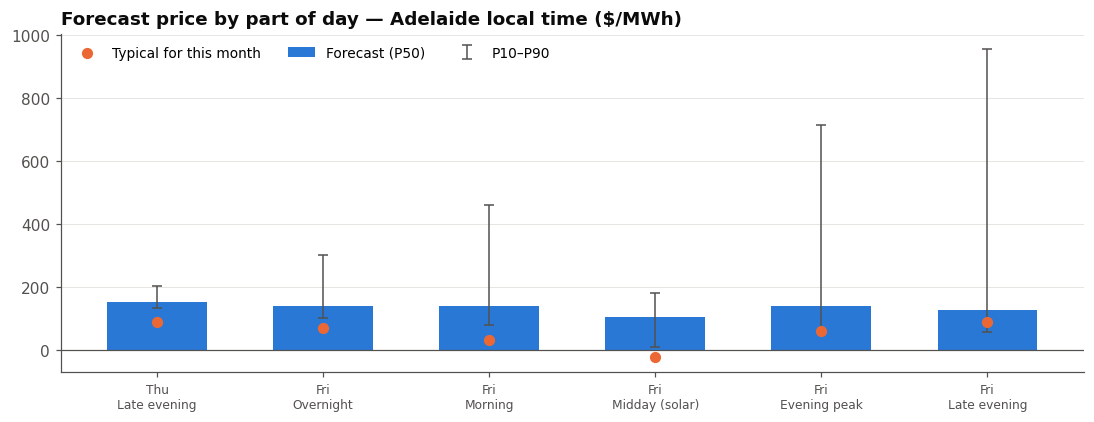

In [26]:
# CHART — the part-of-day forecast as bars (with P10–P90 whiskers); orange dots = typical price for this month.

fig, ax = plt.subplots(figsize=(12, 4))
seg = segments.reset_index()
labels = [f"{pd.Timestamp(d):%a}\n{s}" for d, s in zip(seg["date"], seg["segment"])]
x = np.arange(len(seg))
ax.bar(x, seg["forecast $/MWh"], width=0.6, color=SERIES[0], label="Forecast (P50)")
ax.errorbar(x, seg["forecast $/MWh"], yerr=[seg["forecast $/MWh"] - seg["low (P10)"], seg["high (P90)"] - seg["forecast $/MWh"]],
            fmt="none", ecolor=MUTED, elinewidth=1, capsize=3, label="P10–P90")
ax.scatter(x, seg["typical for month"], color=SERIES[1], s=40, zorder=3, label="Typical for this month")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xticks(x, labels, fontsize=8)
ax.set_title("Forecast price by part of day — Adelaide local time ($/MWh)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3, fontsize=9)
plt.show()

### Live check: how did the models do over the last 24 hours?

Rolling forecasts for every interval in the last day of live data, made 1 h and 24 h ahead, compared with what actually happened. The first run backfills about two days of AEMO pre-dispatch runs (hourly, ~50 MB); later runs only fetch what's new.

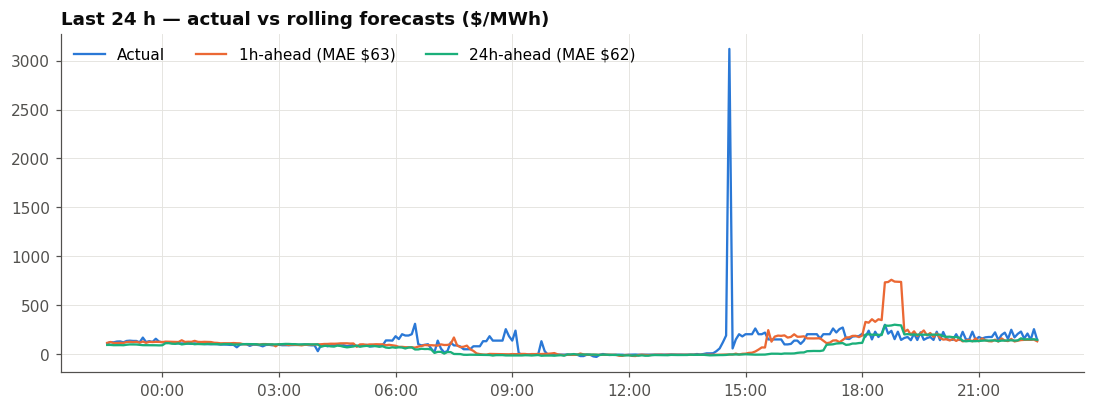

In [27]:
# LIVE CHECK — re-forecasts every interval of the last 24 hours exactly 1 h and 24 h ahead (using only data that
# was available at the time) and compares them with what actually happened. The first run backfills ~2 days of
# AEMO runs (hourly, ~50 MB); later runs only fetch what's new.

def rolling_forecast(name, index):
    # forecast every interval in `index` exactly `name` ahead, using only data available at that time
    k = HORIZONS[name]
    known = _known_series()
    grid = _grid(known, index.min() - pd.Timedelta(days=10), index.max())
    X = calendar_features(index).join(price_features(grid, k).reindex(index)) \
                                .join(aemo_features(index, index - k * STEP, predispatch_all()))
    return horizon_predict(name, X)

if LIVE_OK:
    known = _known_series()
    idx = known.index[known.index > known.index.max() - pd.Timedelta(days=1)]
    try:
        update_live_predispatch(since=idx.min() - pd.Timedelta(hours=26), every=2)
        _pd_checked = pd.Timestamp(0)                      # force predispatch_all() to reload
    except Exception as exc:
        print(f"(pre-dispatch backfill failed: {exc})")
    fig, ax = plt.subplots()
    ax.plot(idx, known.loc[idx], color=SERIES[0], label="Actual")
    for name, color in [("1h", SERIES[1]), ("24h", SERIES[2])]:
        f = rolling_forecast(name, idx)
        mae = (known.loc[idx] - f["p50"]).abs().mean()
        ax.plot(idx, f["p50"], color=color, label=f"{name}-ahead (MAE ${mae:.0f})")
    ax.set_title("Last 24 h — actual vs rolling forecasts ($/MWh)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.legend(loc="upper left", ncol=3)
    plt.show()

## 11. Notes & limitations

* **Accuracy depends on the horizon.** Within a few hours the models are good, helped most by AEMO's pre-dispatch forecast; beyond ~40 h no AEMO run covers the target and accuracy drops back towards the price-history-only level; beyond 48 h it's the seasonal model.
* **Spikes aren't predictable from price history alone.** Extreme events (interconnector outages, low-wind evenings, $17,500 price-cap intervals) mostly show up only as a wide P10–P90 band.
* **Seasonal model ≠ forecast of the future market.** Far-ahead predictions are "what this time usually looks like given recent years" — tree models don't extrapolate trends, so structural shifts (new batteries, more rooftop solar) appear only once they're in the data.
* **Improvements worth trying:** AEMO's 7-day pre-dispatch (`Reports/Current/PD7Day`) to extend AEMO coverage to several days, P5MIN for the next hour, demand and wind/solar forecasts, BOM temperature, interconnector flows, and a rolling-origin backtest across several seasons (the test set here is Apr–Sep only).
* **Refreshing the history:** rerun `scripts/download_history.py` and `scripts/download_predispatch.py` each month (AEMO publishes the monthly archives ~1–2 weeks after month-end); the live API and the NEMWeb "Current" folder fill the gap in between. After refreshing, rerun the notebook to retrain (~15 min).

## 12. Enter a date and time → predicted price

Two ways to ask for a prediction:

* **Simple** — edit `WHEN` (and `TZ`) in the first cell below and run it.
* **Form** — run the second cell, type a date and time in the box, pick the time zone and press **Predict**. (The form needs a Jupyter front end with widget support, such as JupyterLab or VS Code.)

Accepted formats include `2026-10-31 18:30`, `31/10/2026 6:30pm` and `2026-11-02 07:00`. The answer covers the 5-minute interval that contains that time: the predicted price with its likely range, AEMO's own forecast (if one covers that time), the typical price for that hour in that month, and the actual price if it has already happened.

This uses the models trained above, so run the whole notebook first (or at least once per session).

In [28]:
# PREDICTION FOR ONE DATE & TIME — edit WHEN / TZ and run this cell.
#   WHEN: the date and time you want a price for
#   TZ:   "Australia/Adelaide" for Adelaide local time, or None for NEM time (AEST, UTC+10)

WHEN = "2026-10-31 18:30"
TZ = "Australia/Adelaide"

def show_prediction(when, tz="Australia/Adelaide"):
    # Predicted (and, if known, actual) price for the 5-minute interval containing `when`, as a small table
    tz_label = tz or "NEM time"
    try:
        t_in = pd.Timestamp(when) if not isinstance(when, str) else pd.to_datetime(when, dayfirst="/" in when)
    except (ValueError, TypeError):
        print(f"Couldn't read '{when}' as a date and time — try something like 2026-10-31 18:30")
        return None
    r = price_at(t_in, tz=tz)
    end_nem = r["interval_end_nem"]
    end_loc = end_nem if tz is None else end_nem.tz_localize(NEM_TZ).tz_convert(tz).tz_localize(None)
    start_loc = end_loc - STEP

    # typical price for this hour of day in this month, from the 5-year history (in the chosen time zone)
    hist_loc = price.index if tz is None else (price.index - STEP).tz_localize(NEM_TZ).tz_convert(tz).tz_localize(None)
    typical = price[(hist_loc.month == start_loc.month) & (hist_loc.hour == start_loc.hour)].median()

    money = lambda v: "—" if v is None or pd.isna(v) else f"${v:,.2f}/MWh  ({v / 10:,.1f} c/kWh)"
    p50 = r["predicted_p50"]
    verdict = ("cheaper than usual" if p50 < typical - 15 else
               "more expensive than usual" if p50 > typical + 15 else "about usual")
    rows = {
        "Time asked for": f"{t_in:%a %d %b %Y %H:%M} ({tz_label})",
        "5-min interval": f"{start_loc:%H:%M}–{end_loc:%H:%M} ({tz_label}),  ends {end_nem:%H:%M} NEM time",
        "Predicted price (P50)": money(p50),
        "Likely range (P10–P90)": f"${r['predicted_p10']:,.0f} to ${r['predicted_p90']:,.0f}/MWh",
        "AEMO pre-dispatch forecast": money(r["aemo_forecast"]),
        "Typical for this hour & month": f"{money(typical)}  → prediction is {verdict}",
        "Actual price": money(r["actual"]) + ("" if r["actual"] is None else f"   [{r['actual_source']}]"),
        "Model used": f"{r['model']}  (forecast made from prices up to {r['forecast_as_of']:%a %d %b %H:%M} NEM time)",
    }
    if p50 < 0:
        rows["What it means"] = "Negative price expected: a good time to use or store power; avoid exporting"
    table = pd.DataFrame({"": list(rows.values())}, index=list(rows.keys()))
    display(table.style.set_properties(**{"text-align": "left"}))
    return r

result = show_prediction(WHEN, TZ)

,
Time asked for,Sat 31 Oct 2026 18:30 (Australia/Adelaide)
5-min interval,"18:30–18:35 (Australia/Adelaide), ends 18:05 NEM time"
Predicted price (P50),$48.07/MWh (4.8 c/kWh)
Likely range (P10–P90),$-28 to $99/MWh
AEMO pre-dispatch forecast,—
Typical for this hour & month,$103.97/MWh (10.4 c/kWh) → prediction is cheaper than usual
Actual price,$45.94/MWh (4.6 c/kWh) [OpenElectricity API]
Model used,24h-ahead (forecast made from prices up to Fri 30 Oct 18:05 NEM time)


In [29]:
# PREDICTION FORM — type a date & time, choose the time zone and press Predict (or Enter).
# Needs widget support (JupyterLab / VS Code). Results appear under the form and update on every click.

import ipywidgets as widgets
from IPython.display import clear_output

when_box = widgets.Text(value=WHEN, placeholder="e.g. 2026-10-31 18:30", description="Date & time",
                        continuous_update=False, style={"description_width": "85px"}, layout=widgets.Layout(width="300px"))
tz_box = widgets.Dropdown(options=[("Adelaide local time", "Australia/Adelaide"), ("NEM time (AEST)", "NEM")],
                          value="Australia/Adelaide", description="Time zone", layout=widgets.Layout(width="260px"))
go = widgets.Button(description="Predict", button_style="primary", icon="bolt")
out = widgets.Output()

def _predict(_=None):
    with out:
        clear_output()
        show_prediction(when_box.value, None if tz_box.value == "NEM" else tz_box.value)

go.on_click(_predict)
when_box.observe(lambda change: _predict(), names="value")      # pressing Enter in the box also predicts
display(widgets.HBox([when_box, tz_box, go]), out)
_predict()

Output()

## 13. Daily plan — when to export solar and when to take from the grid

`daily_plan(day)` turns the forecast for one day into a **half-hour-by-half-hour action plan** in local time, then merges neighbouring half-hours with the same action into blocks, e.g. *"10:00–15:30 Don't export — use / store power"*.

**How each half-hour is classified**

1. **Is the sun useful?** Sunrise and sunset for Adelaide are calculated for that date (NOAA solar-position formula). Panels are treated as producing usefully from 1 h after sunrise to 1 h before sunset (`SOLAR_MARGIN_H`).
2. **Is the price cheap, normal or expensive?** By default this is *relative to the rest of that day*: the cheapest 25% of the day's half-hours are "cheap" and the most expensive 25% are "expensive". You can set fixed thresholds in c/kWh instead (`import_below_c`, `export_above_c`). A negative price always counts as cheap. To ignore noise on flat days, a half-hour must also be at least 2 c/kWh from the day's median (`MIN_GAP_C`), and blocks shorter than 1 h are merged into the block before (`MIN_BLOCK_H`). Negative-price periods are never merged away.
3. **Combine the two:**

| | Sun up | Sun down |
|---|---|---|
| **Price negative** | Don't export — use / store power (you'd pay to export) | Take from grid — you're paid to use power |
| **Cheap** | Use your solar / charge battery; grid top-up is fine | Take from grid — charge battery, run big loads |
| **Normal** | Self-use; export any surplus | Normal use |
| **Expensive** | **Export solar** | Avoid grid — run on battery / export battery |

With `has_battery=False`, "export battery" becomes "minimise use", and charging advice is dropped.

The P10–P90 column shows the uncertainty. If the low end of an "export" block is still well above zero, it's a confident call.

> These are **wholesale** prices. They only reach your bill on a pass-through plan (e.g. Amber) or a VPP, and network charges are added on top. On a fixed time-of-use plan, follow that plan's tariff times instead.

Plan for Thursday 12 November 2026 (Australia/Adelaide) — forecast from prices up to Thu 12 Nov 22:30 NEM time
Sunrise 06:04, sunset 19:55; useful solar 07:04–18:55
Price levels relative to this day: cheap ≤ 7.4 c/kWh, expensive ≥ 17.5 c/kWh;  battery: yes


from,to,hours,what to do,avg c/kWh,range c/kWh (P10–P90)
23:00,00:00,1.0,Normal use,15.5,13.4 to 20.4


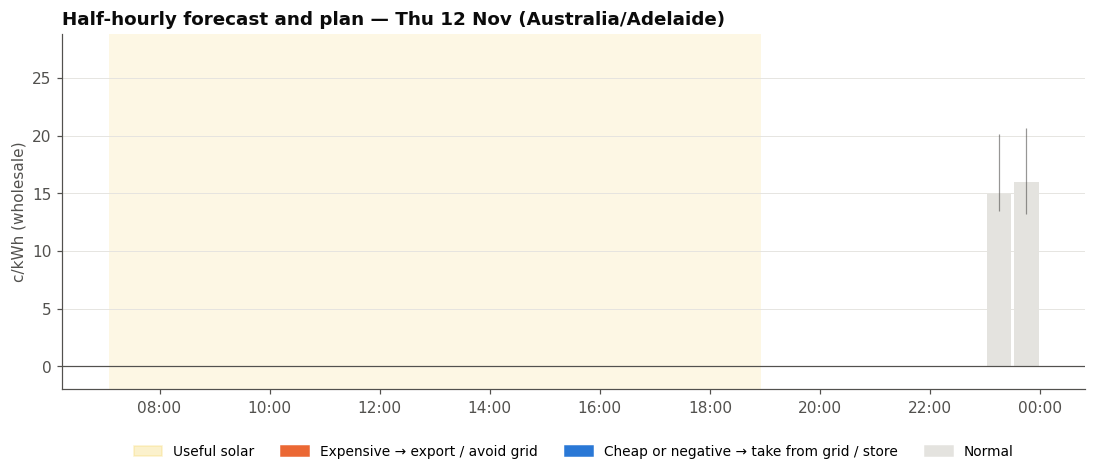

In [30]:
# DAILY SOLAR / GRID PLAN — set the options, run, and read the blocks table + chart.
#   DAY:          "today" (rest of today), "tomorrow", or a date like "2026-11-14"
#   HAS_BATTERY:  True if you have a home battery (changes the night-time advice)
#   Thresholds:   None = relative to the day (cheapest / dearest 25%); or set fixed c/kWh values

DAY = "today"
TZ = "Australia/Adelaide"
HAS_BATTERY = True
IMPORT_BELOW_C = None      # e.g. 5   → half-hours below 5 c/kWh count as cheap
EXPORT_ABOVE_C = None      # e.g. 15  → half-hours above 15 c/kWh count as expensive

ADELAIDE_LAT, ADELAIDE_LON = -34.93, 138.60
SOLAR_MARGIN_H = 1.0       # panels produce little in the first / last hour of daylight
MIN_GAP_C = 2.0            # cheap / expensive must also be ≥ this far from the day's median (ignores flat days' noise)
MIN_BLOCK_H = 1.0          # blocks shorter than this merge into the block before them (no 30-min flip-flopping)

ACTION_TEXT = {
    ("neg", True):  "Don't export — use / store power (export would cost you)",
    ("neg", False): "Take from grid — you're paid to use power",
    ("cheap", True):  "Use your solar / charge battery — grid top-up is fine",
    ("cheap", False): "Take from grid — charge battery, run big loads",
    ("normal", True):  "Self-use, export any surplus",
    ("normal", False): "Normal use",
    ("dear", True):  "Export solar",
    ("dear", False): "Avoid grid — run on battery / export battery",
}
NO_BATTERY_TEXT = {
    ("cheap", True):  "Use your solar — run big loads now",
    ("cheap", False): "Take from grid — run big loads now",
    ("dear", False): "Avoid grid — minimise use",
}
# chart colour by what you do with the grid: export / import / self-use / neutral
ACTION_COLOR = {"dear": SERIES[1], "cheap": SERIES[0], "neg": SERIES[0], "normal": GRID}

def sun_times(day, tz=TZ, lat=ADELAIDE_LAT, lon=ADELAIDE_LON):
    # Sunrise / sunset (local, naive) from the NOAA solar-position approximation
    day = pd.Timestamp(day).normalize()
    g = 2 * np.pi / 365 * (day.dayofyear - 1)
    eqtime = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    phi = np.radians(lat)
    ha = np.degrees(np.arccos(np.cos(np.radians(90.833)) / (np.cos(phi) * np.cos(decl)) - np.tan(phi) * np.tan(decl)))
    to_local = lambda minutes: (day + pd.Timedelta(minutes=minutes)).tz_localize("UTC").tz_convert(tz).tz_localize(None)
    return to_local(720 - 4 * (lon + ha) - eqtime), to_local(720 - 4 * (lon - ha) - eqtime)

def daily_plan(day="today", tz=TZ, has_battery=HAS_BATTERY, import_below_c=None, export_above_c=None, show=True):
    now_loc = pd.Timestamp.now(tz=tz).tz_localize(None)
    d = (now_loc.normalize() if day == "today" else
         now_loc.normalize() + pd.Timedelta(days=1) if day == "tomorrow" else pd.Timestamp(day).normalize())

    # forecast every 5-min interval of that local day (only the future part of today)
    as_of = _known_series().index.max()
    to_nem = lambda t: t.tz_localize(tz).tz_convert(NEM_TZ).tz_localize(None)
    start_nem, end_nem = max(to_nem(d) + STEP, as_of + STEP), to_nem(d + pd.Timedelta(days=1))
    if start_nem > end_nem:
        print(f"{d:%a %d %b %Y} is already over — pick 'today', 'tomorrow' or a future date.")
        return None
    f = forecast(pd.date_range(start_nem, end_nem, freq=STEP), as_of)

    # half-hours in local time (labelled by their start)
    f.index = (f.index - STEP).tz_localize(NEM_TZ).tz_convert(tz).tz_localize(None)
    hh = f[["p10", "p50", "p90"]].resample("30min").mean().dropna() / 10        # → c/kWh

    # 1) sun up?  2) cheap / normal / dear?  3) action
    sunrise, sunset = sun_times(d, tz)
    margin = pd.Timedelta(hours=SOLAR_MARGIN_H)
    sun = (hh.index >= sunrise + margin) & (hh.index + pd.Timedelta("30min") <= sunset - margin)
    # "cheap" / "expensive" are judged against the WHOLE day: actual prices for the part already over,
    # forecasts for the rest — so a plan made late in the day isn't ranked against just a few half-hours
    known = _known_series()
    done = known[(known.index > to_nem(d)) & (known.index <= as_of)]
    done.index = (done.index - STEP).tz_localize(NEM_TZ).tz_convert(tz).tz_localize(None)
    whole_day = pd.concat([done.resample("30min").mean().dropna() / 10, hh["p50"]])
    lo = import_below_c if import_below_c is not None else whole_day.quantile(0.25)
    hi = export_above_c if export_above_c is not None else whole_day.quantile(0.75)
    mid = whole_day.median()
    cheap = (hh["p50"] <= lo) & (hh["p50"] <= mid - MIN_GAP_C)
    dear = (hh["p50"] >= hi) & (hh["p50"] >= mid + MIN_GAP_C) & (hh["p50"] > 0)
    level = pd.Series(np.where(hh["p50"] < 0, "neg", np.where(cheap, "cheap", np.where(dear, "dear", "normal"))),
                      index=hh.index)
    # smooth out short runs: a run under MIN_BLOCK_H takes the level of the run before it (or after, at the start)
    min_len = int(MIN_BLOCK_H * 2)
    for _ in range(3):
        run = (level != level.shift()).cumsum()
        sizes = level.groupby(run).transform("size")
        short = (sizes < min_len) & (level != "neg")          # never hide a negative-price period
        if not short.any():
            break
        prev = level.where(~short).ffill().bfill()
        level = level.where(~short, prev)
    level = level.values
    texts = {**ACTION_TEXT, **({} if has_battery else NO_BATTERY_TEXT)}
    hh = hh.assign(sun=sun, level=level, action=[texts[(l, s)] for l, s in zip(level, sun)])

    # merge neighbouring half-hours with the same action into blocks
    block_id = (hh["action"] != hh["action"].shift()).cumsum()
    blocks = pd.DataFrame([{
        "from": g.index[0].strftime("%H:%M"), "to": (g.index[-1] + pd.Timedelta("30min")).strftime("%H:%M"),
        "hours": len(g) / 2, "what to do": g["action"].iloc[0],
        "avg c/kWh": g["p50"].mean(), "range c/kWh (P10–P90)": f"{g['p10'].mean():.1f} to {g['p90'].mean():.1f}",
    } for _, g in hh.groupby(block_id)])

    if show:
        basis = (f"fixed: cheap ≤ {lo:.1f} c, expensive ≥ {hi:.1f} c" if import_below_c is not None or export_above_c is not None
                 else f"relative to this day: cheap ≤ {lo:.1f} c/kWh, expensive ≥ {hi:.1f} c/kWh")
        print(f"Plan for {d:%A %d %B %Y} ({tz}) — forecast from prices up to {as_of:%a %d %b %H:%M} NEM time")
        print(f"Sunrise {sunrise:%H:%M}, sunset {sunset:%H:%M}; useful solar {sunrise + margin:%H:%M}–{sunset - margin:%H:%M}")
        print(f"Price levels {basis};  battery: {'yes' if has_battery else 'no'}")
        display(blocks.style.format({"hours": "{:.1f}", "avg c/kWh": "{:.1f}"}).hide(axis="index"))

        fig, ax = plt.subplots(figsize=(12, 4.2))
        x = hh.index + pd.Timedelta("15min")
        ax.axvspan(sunrise + margin, sunset - margin, color="#f5d76e", alpha=0.18, linewidth=0, label="Useful solar")
        ax.bar(x, hh["p50"], width=pd.Timedelta("27min"), color=[ACTION_COLOR[l] for l in hh["level"]])
        ax.errorbar(x, hh["p50"], yerr=[hh["p50"] - hh["p10"], hh["p90"] - hh["p50"]],
                    fmt="none", ecolor=MUTED, elinewidth=0.8, alpha=0.6)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        from matplotlib.patches import Patch
        handles = [Patch(color="#f5d76e", alpha=0.35, label="Useful solar"),
                   Patch(color=SERIES[1], label="Expensive → export / avoid grid"),
                   Patch(color=SERIES[0], label="Cheap or negative → take from grid / store"),
                   Patch(color=GRID, label="Normal")]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)
        lo_y = min(np.nanpercentile(hh["p10"], 2), 0) - 2
        hi_y = max(hh["p50"].max() * 1.8, hh["p50"].max() + 8)            # keep the bars readable
        ax.set_ylim(lo_y, hi_y)
        if hh["p90"].max() > hi_y:
            ax.text(0.99, 0.97, f"Upper range clipped — spike risk up to {hh['p90'].max():.0f} c/kWh (see table)",
                    transform=ax.transAxes, ha="right", va="top", fontsize=9, color=MUTED)
        ax.set_ylabel("c/kWh (wholesale)")
        ax.set_title(f"Half-hourly forecast and plan — {d:%a %d %b} ({tz})")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.grid(axis="x", visible=False)
        plt.show()
    return {"half_hourly": hh, "blocks": blocks, "sunrise": sunrise, "sunset": sunset}

plan_day = daily_plan(DAY, TZ, HAS_BATTERY, IMPORT_BELOW_C, EXPORT_ABOVE_C)

Plan for Friday 13 November 2026 (Australia/Adelaide) — forecast from prices up to Thu 12 Nov 22:30 NEM time
Sunrise 06:03, sunset 19:56; useful solar 07:03–18:56
Price levels relative to this day: cheap ≤ 10.5 c/kWh, expensive ≥ 14.7 c/kWh;  battery: yes


from,to,hours,what to do,avg c/kWh,range c/kWh (P10–P90)
00:00,05:30,5.5,Normal use,13.9,10.2 to 27.1
05:30,07:00,1.5,Avoid grid — run on battery / export battery,16.7,11.1 to 68.8
07:00,07:30,0.5,Normal use,14.5,7.8 to 58.7
07:30,09:30,2.0,"Self-use, export any surplus",12.6,6.1 to 26.0
09:30,15:30,6.0,Use your solar / charge battery — grid top-up is fine,10.1,0.4 to 16.7
15:30,18:30,3.0,"Self-use, export any surplus",11.5,4.6 to 19.5
18:30,21:00,2.5,Avoid grid — run on battery / export battery,16.9,7.2 to 125.1
21:00,23:00,2.0,Normal use,14.9,7.9 to 136.0
23:00,00:00,1.0,"Take from grid — charge battery, run big loads",8.5,2.2 to 15.0


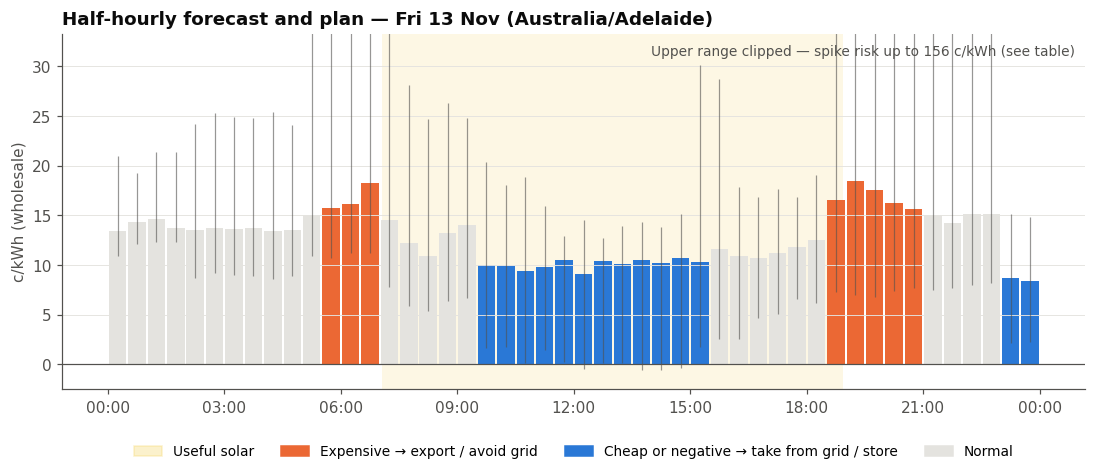

In [31]:
# TOMORROW'S PLAN — the same plan for the whole of tomorrow (handy to check the evening before).
plan_tomorrow = daily_plan("tomorrow", TZ, HAS_BATTERY, IMPORT_BELOW_C, EXPORT_ABOVE_C)